# Examples of Plotting and Animation of Wigner Functions
## Stern Gerlach interferometer

In [1]:
%reload_ext autoreload

import numpy as np 
import matplotlib.pyplot as plt
import math as math 
import cmath as cmath
from scipy import linalg as linalg
from scipy import integrate as integ
from scipy.integrate import solve_ivp



import sys
import os

from gbcs import Quantum_State, Hamiltonian, Decoherence


This is a time independent operator-valued force Hamiltonian
Initializing a Gaussian State


/Users/lorenzobraccini/GitHub/GCS/src/Measurements.py:61: ComplexWarning: Casting complex values to real discards the imaginary part
  prob_t[i,j] = np.trace(rho_q_PMS_unnormalize)
/Users/lorenzobraccini/GitHub/GCS/src/Measurements.py:62: RuntimeWarning: invalid value encountered in divide
  rho_q_t_PMS_array[i,j] = rho_q_PMS_unnormalize/prob_t[i,j]
/Users/lorenzobraccini/GitHub/GCS/src/Wigner_Functions.py:107: ComplexWarning: Casting complex values to real discards the imaginary part
  W_Diag[m,n] += (2**n_modes)*rho_q[i,i]/(np.pi**n_modes * np.sqrt(det_sigma))*np.exp(-np.transpose(r_tilde_array[m,n] - r_JK[i,i])@sigma_inv@(r_tilde_array[m,n] - r_JK[i,i]))[0,0]


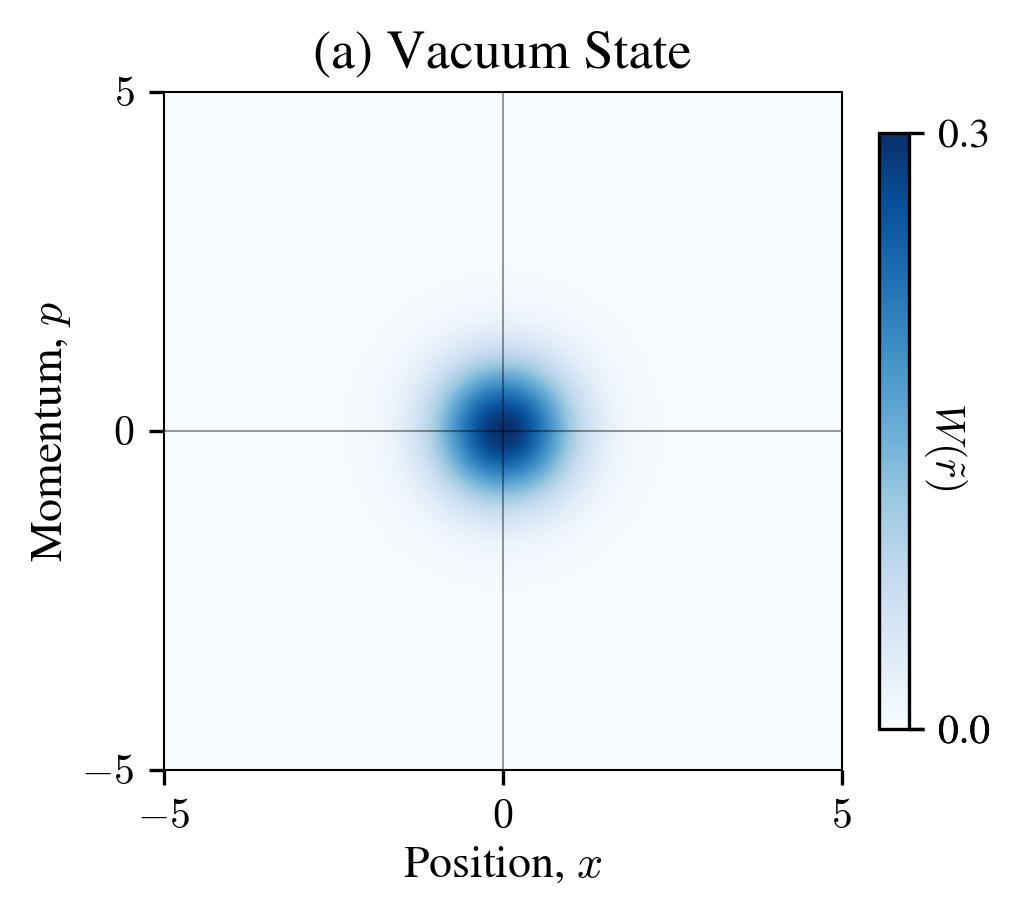

In [2]:
N_qubits = 1
n_modes = 1

########################## Hamiltonians ##########################

H_1_general = Hamiltonian(N_qubits, n_modes)
H_1_force = Hamiltonian(N_qubits, n_modes)

H_null = np.zeros((2*n_modes,2*n_modes)) 
iden = np.eye(2*n_modes)
r_null = np.zeros((2*n_modes,1)) 

H_m = np.eye(2)
r_m =  r_null #np.array([[0.5],[0.0]])
H_q = H_null
r_q = np.array([[0.0],[0.0]])

H_q_0_array = np.array([0 +0*1j])

H_1_force.Initialize_Constant_Hamiltonians([H_m], [r_m, r_q], H_q_0_array)

########################## Initialize State ##########################

s = 1
phi = np.pi/4

r_0 = np.array([[0],
                [0]])
rot = np.array([[np.cos(phi), - np.sin(phi)],[np.sin(phi), np.cos(phi)]])

sigma_0 = rot@np.array([[s,0], [0,1/s]])@np.transpose(rot)

rho_q_0 = np.ones((2*N_qubits,2*N_qubits))/(2**(2*N_qubits))

GCS = Quantum_State(N_qubits, n_modes)
GCS.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)

########################## Dynamics ##########################

t_array = np.linspace(0,0.2*np.pi, 100)

GCS.Unitary_Dynamics_Numerical(H_1_force, t_array)

sigma_x = np.array([[0,1],[1,0]])/2 
steps = 500
mode_number = 0
time_index = 0
bar_limits = [0,0.5]
sigma_para = 4.2
n_frames = len(GCS.t_array)
array_tick = np.linspace(-5,5,3)
GCS.Qubit_Ideal_Measurament(sigma_x, 'Time')

title = '(a) Vacuum State'
save = 'vaccum_state.png'

GCS.Plot_Wigner_Function_Diag(steps, time_index, mode_number, sigma_para, array_tick, title, save)



## Plot of First Moments, Cantrasts and Phases of the Qubi Reduced Density Matrix

/opt/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/opt/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


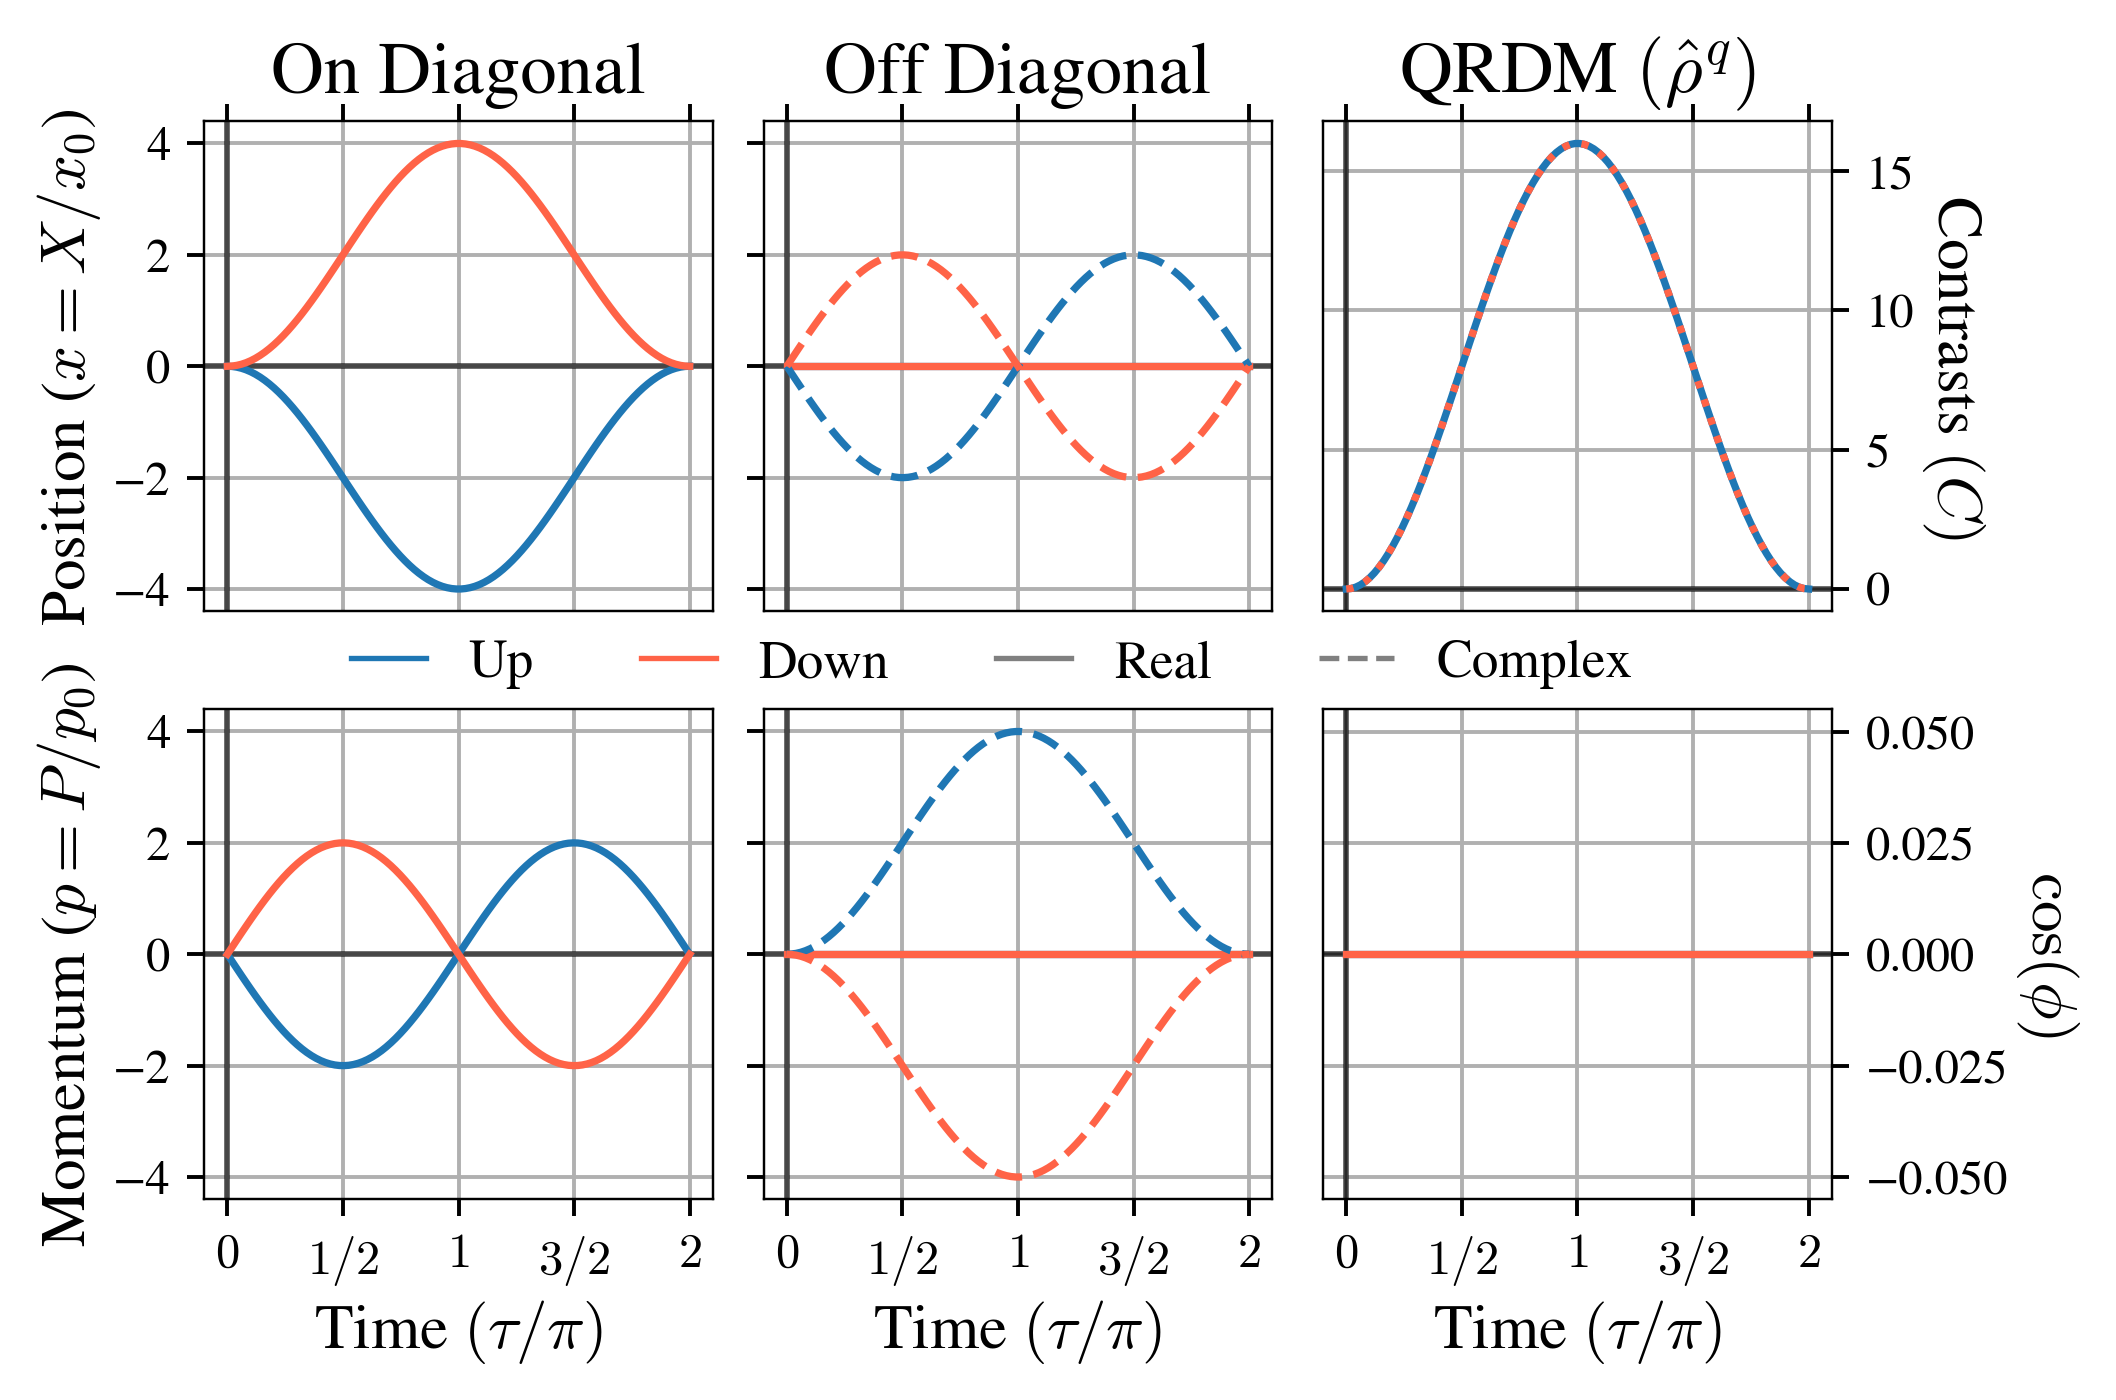

In [3]:
Parameter_list = []
array_pi = np.linspace(0,2,5)

GCS.Plot_Phase_Space_First_QRDM(Parameter_list, array_pi, False);

## Plots of Wigner Functions: Example of Qubit Measurement

/Users/lorenzobraccini/GitHub/GCS/src/Measurements.py:61: ComplexWarning: Casting complex values to real discards the imaginary part
  prob_t[i,j] = np.trace(rho_q_PMS_unnormalize)
/Users/lorenzobraccini/GitHub/GCS/src/Measurements.py:62: RuntimeWarning: invalid value encountered in divide
  rho_q_t_PMS_array[i,j] = rho_q_PMS_unnormalize/prob_t[i,j]
/Users/lorenzobraccini/GitHub/GCS/src/Wigner_Functions.py:107: ComplexWarning: Casting complex values to real discards the imaginary part
  W_Diag[m,n] += (2**n_modes)*rho_q[i,i]/(np.pi**n_modes * np.sqrt(det_sigma))*np.exp(-np.transpose(r_tilde_array[m,n] - r_JK[i,i])@sigma_inv@(r_tilde_array[m,n] - r_JK[i,i]))[0,0]


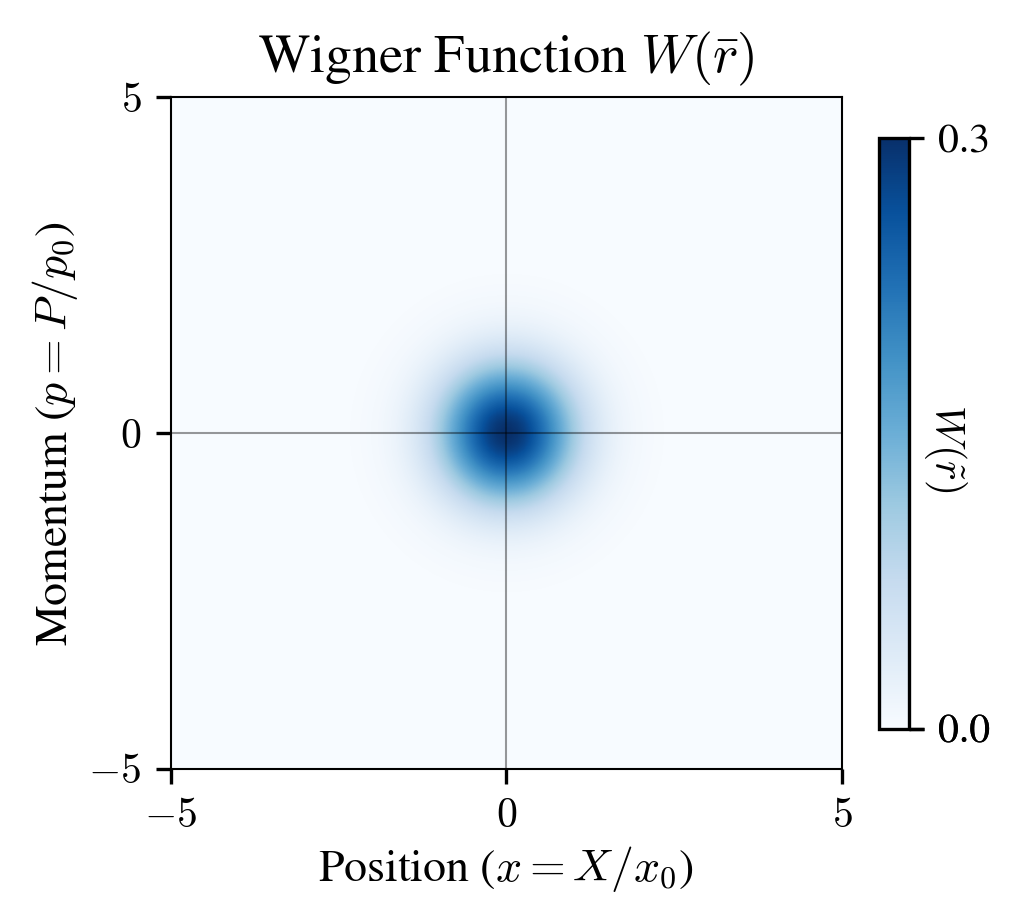

In [4]:
sigma_x = np.array([[0,1],[1,0]])/2 
steps = 100
mode_number = 0
time_index = 1
bar_limits = [0,0.5]
sigma_para = 0.7
n_frames = len(GCS.t_array)
array_tick = np.linspace(-5,5,3)
GCS.Qubit_Ideal_Measurament(sigma_x, 'Time')
GCS.Plot_Wigner_Function_Diag(steps, time_index, mode_number, sigma_para, array_tick, False, False)


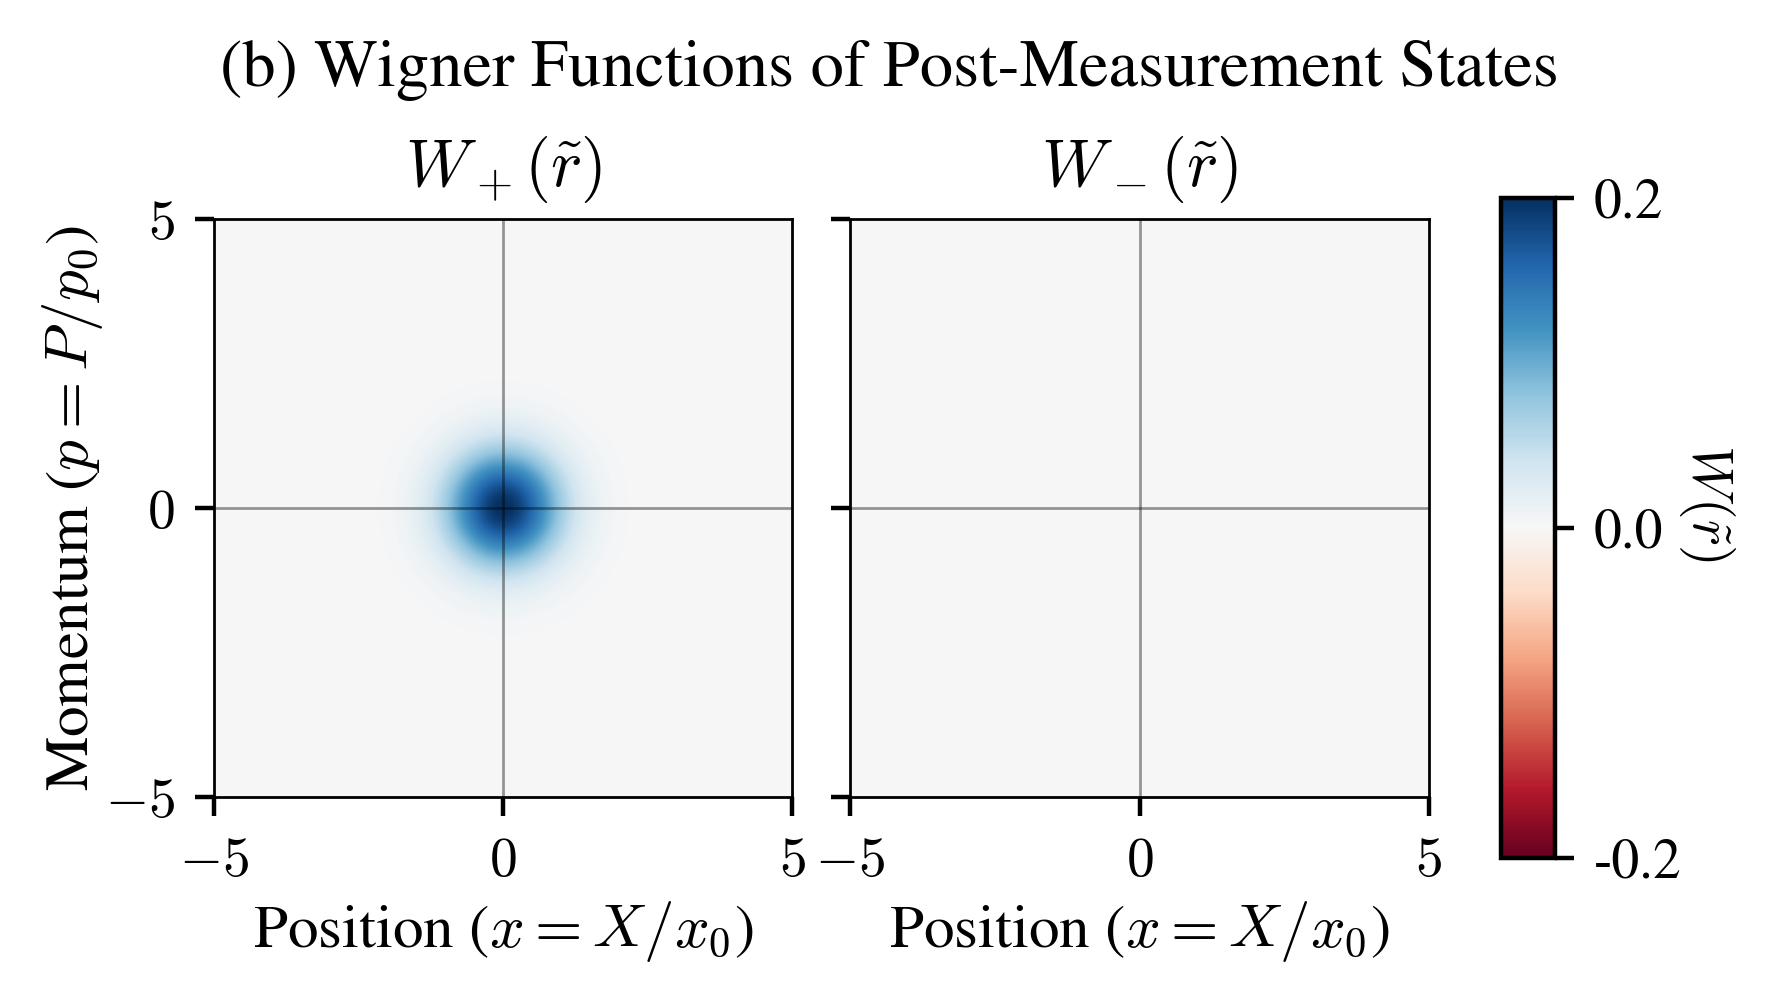

In [5]:
GCS.Plot_Wigner_Function_PMS(steps, time_index, mode_number, sigma_para, array_tick, False, False)

## Animation of Wigner Functions

/Users/lorenzobraccini/GitHub/GCS/src/Wigner_Functions.py:107: ComplexWarning: Casting complex values to real discards the imaginary part
  W_Diag[m,n] += (2**n_modes)*rho_q[i,i]/(np.pi**n_modes * np.sqrt(det_sigma))*np.exp(-np.transpose(r_tilde_array[m,n] - r_JK[i,i])@sigma_inv@(r_tilde_array[m,n] - r_JK[i,i]))[0,0]


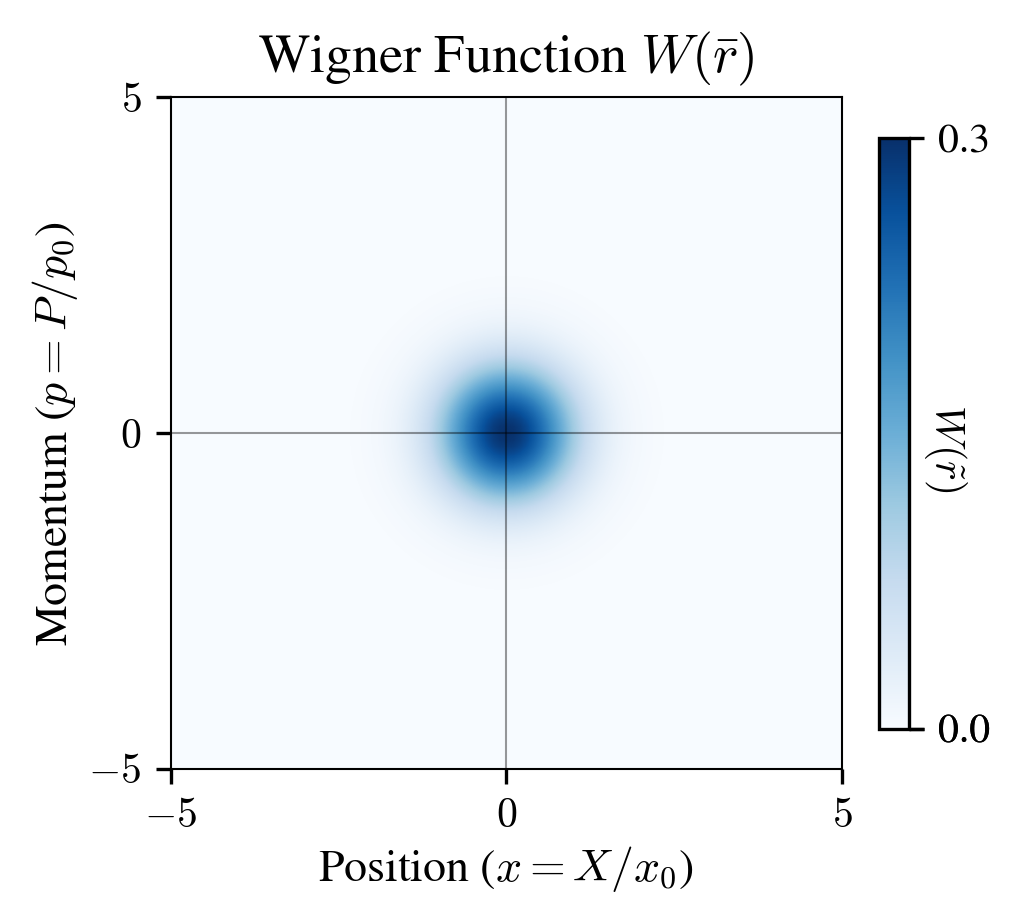

In [7]:
steps = 101
mode_number = 0
time_index = 40
bar_limits = [0,0.5]
sigma_para = 0.6
array_tick = np.linspace(-5,5,3)
n_frames = len(GCS.t_array)

GCS.Animate_Wigner_Function_Diag(steps, mode_number, sigma_para, array_tick, n_frames, False, False)

In [ ]:
GCS.Animate_Wigner_Function_PMS(steps, mode_number, sigma_para, array_tick, n_frames, False, False)

This is a time independent gaussian Hamiltonian
Initializing a Gaussian State


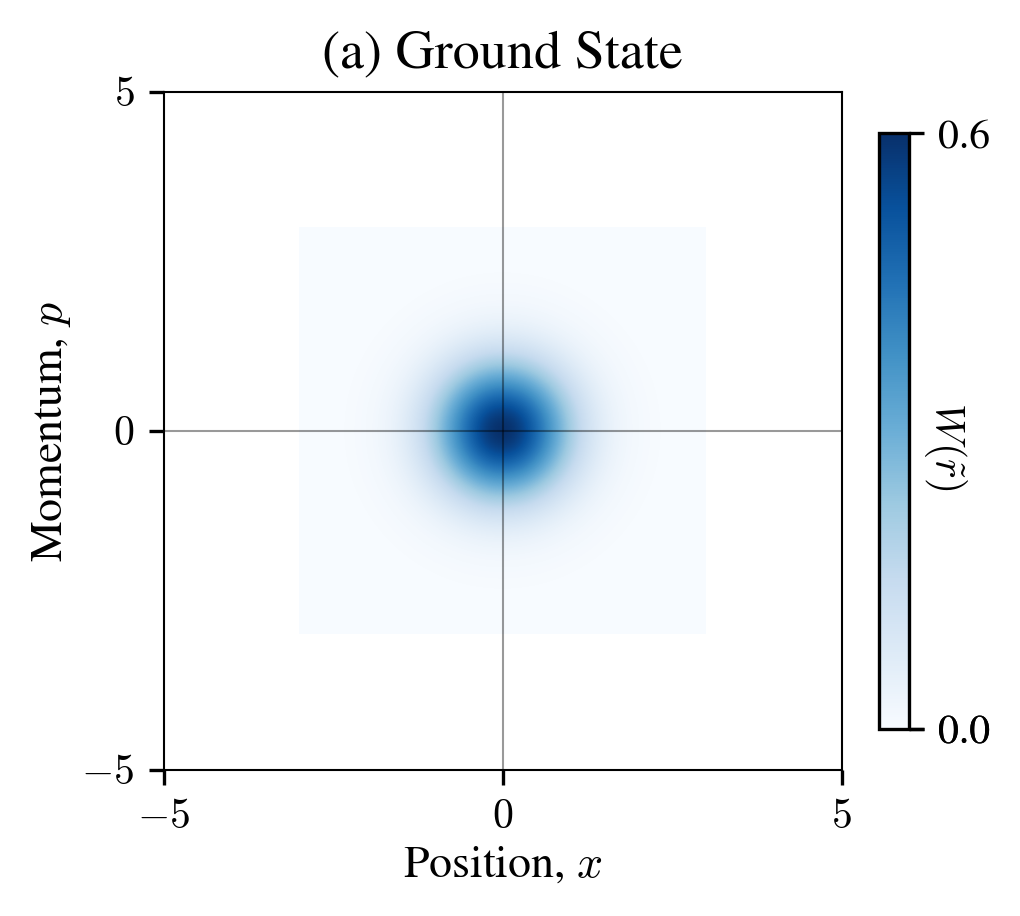

In [6]:
N_qubits = 1
n_modes = 1

########################## Hamiltonians ##########################

H_1_general = Hamiltonian(N_qubits, n_modes)
H_1_force = Hamiltonian(N_qubits, n_modes)

H_null = np.zeros((2*n_modes,2*n_modes)) 
iden = np.eye(2*n_modes)
r_null = np.zeros((2*n_modes,1)) 

H_m = np.eye(2)
r_m =  r_null #np.array([[0.5],[0.0]])
H_q = H_null
r_q = 2*np.array([[1.0],[0.0]])

H_q_0_array = np.array([0 +0*1j])

H_1_force.Initialize_Constant_Hamiltonians([H_m], [r_m], H_q_0_array)

########################## Initialize State ##########################

r_0 = np.array([[0.0],
                [0.0]])
sigma_0 = iden
rho_q_0 = np.ones((2*N_qubits,2*N_qubits))/(2**(2*N_qubits))

GCS = Quantum_State(N_qubits, n_modes)
GCS.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)

########################## Dynamics ##########################

t_array = np.linspace(0,2*np.pi, 100)

GCS.Unitary_Dynamics_Numerical(H_1_force, t_array)

title = '(a) Ground State'

GCS.Animate_Gaussian(steps, mode_number, sigma_para, array_tick, n_frames, title, False)

This is a time independent operator-valued general Hamiltonian
This is a time independent operator-valued force Hamiltonian
This is a time independent gaussian Hamiltonian
Initializing a Gaussian State
Initializing a Gaussian State
Initializing a Gaussian State
Computing the Gaussian Time-Indipendent Dynamics of a Gaussian State


/opt/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/opt/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


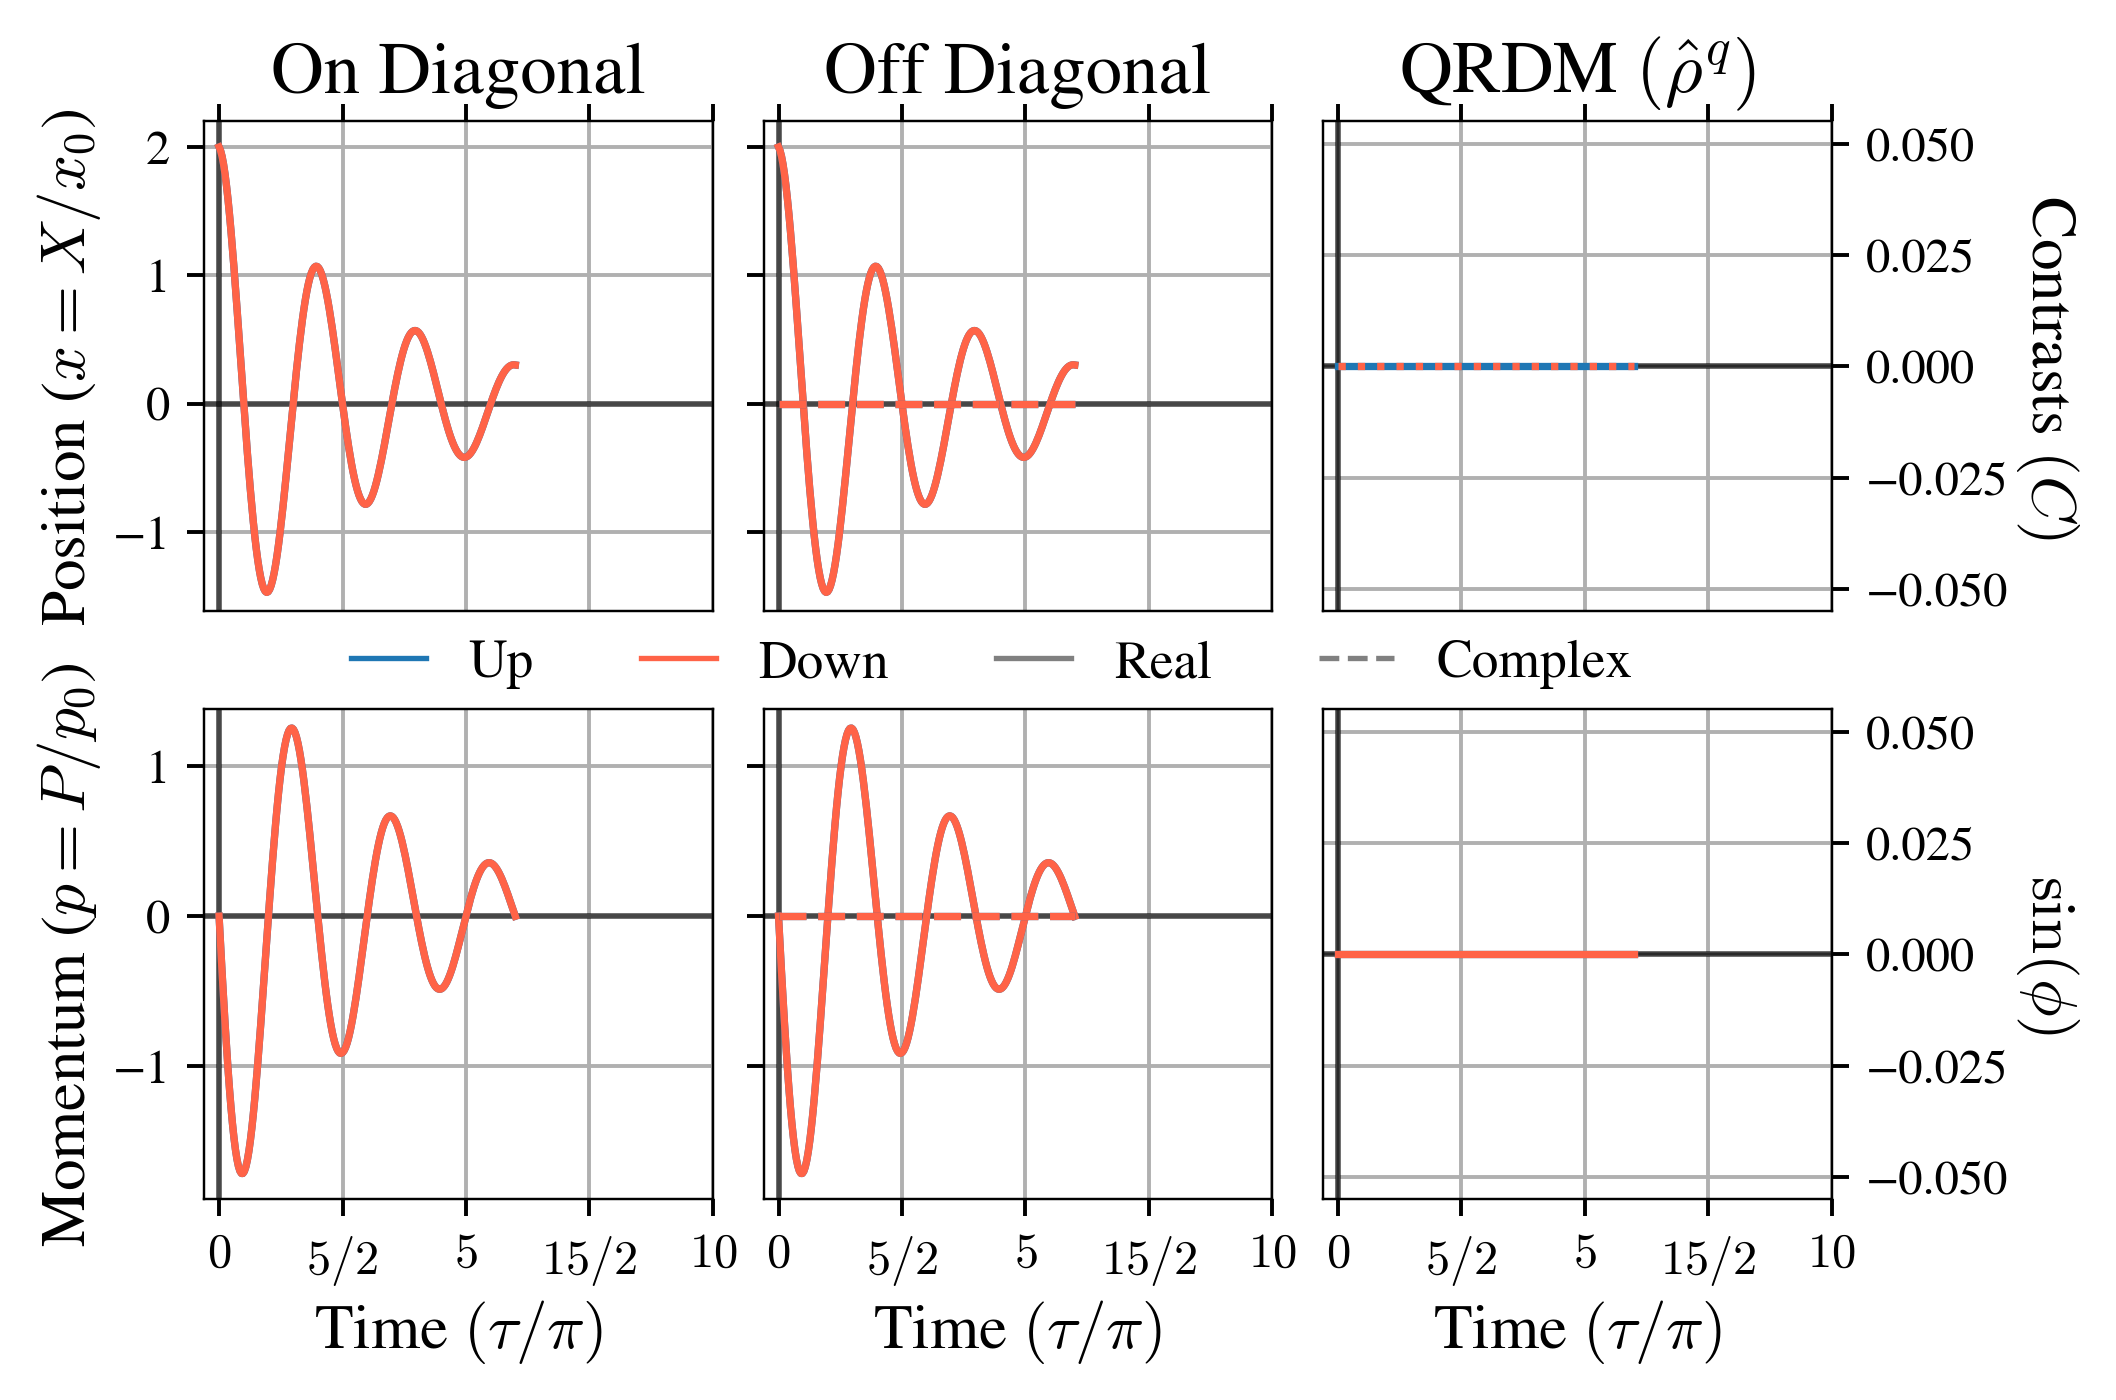

In [22]:
gamma_C = 0.2
gamma_S = 0.2

N_qubits = 1
n_modes = 1

B_a = gamma_C*np.array([[0.,1.],[0.,0.]])

Dec = Decoherence(N_qubits,n_modes,'Ladder', B_a)


########################## Hamiltonians ##########################

H_1_general = Hamiltonian(N_qubits, n_modes)
H_1_force = Hamiltonian(N_qubits, n_modes)
H_1_gauss = Hamiltonian(N_qubits, n_modes)

H_null = np.zeros((2*n_modes,2*n_modes)) 
iden = np.eye(2*n_modes)
r_null = np.zeros((2*n_modes,1)) 

H_m = np.eye(2)
r_m = r_null
H_q = H_null
r_q = r_null

H_q_0_array = np.array([0 +0*1j])

H_1_general.Initialize_Constant_Hamiltonians([H_m, H_q], [r_m, r_q], H_q_0_array)
H_1_force.Initialize_Constant_Hamiltonians([H_m], [r_m, r_q], H_q_0_array)
H_1_gauss.Initialize_Constant_Hamiltonians([H_m], [r_m], H_q_0_array)

########################## Initialize State ##########################
s = 1/2
r_0 = np.array([[2.0],
                [0.0]])
sigma_0 = np.array([[1.0/s,0],
                [0, s]])
rho_q_0 = np.ones((2*N_qubits,2*N_qubits))/(2**(2*N_qubits))

gaussian_state_general = Quantum_State(N_qubits, n_modes)
gaussian_state_general.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)
gaussian_state_force = Quantum_State(N_qubits, n_modes)
gaussian_state_force.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)
gaussian_state_gauss = Quantum_State(N_qubits, n_modes)
gaussian_state_gauss.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)

########################## Dynamics ##########################

t_array = np.linspace(0,6*np.pi, 200)

gaussian_state_general.Open_Dynamics_Numerical(H_1_general, Dec,t_array)
#gaussian_state_force.Open_Dynamics_Numerical(H_1_force,E,D, t_array)
gaussian_state_gauss.Open_Dynamics_Numerical(H_1_gauss, Dec ,t_array)

########################## Plot First Moments ##########################
Parameter_list = []
array_pi = np.linspace(0,10,5)

gaussian_state_general.Plot_Phase_Space_First_QRDM(Parameter_list, array_pi, False);

/opt/anaconda3/lib/python3.11/site-packages/numpy/linalg/linalg.py:2180: RuntimeWarning: divide by zero encountered in det
  r = _umath_linalg.det(a, signature=signature)
/opt/anaconda3/lib/python3.11/site-packages/numpy/linalg/linalg.py:2180: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)
/Users/lorenzobraccini/GitHub/GCS/src/Wigner_Functions.py:107: ComplexWarning: Casting complex values to real discards the imaginary part
  W_Diag[m,n] += (2**n_modes)*rho_q[i,i]/(np.pi**n_modes * np.sqrt(det_sigma))*np.exp(-np.transpose(r_tilde_array[m,n] - r_JK[i,i])@sigma_inv@(r_tilde_array[m,n] - r_JK[i,i]))[0,0]


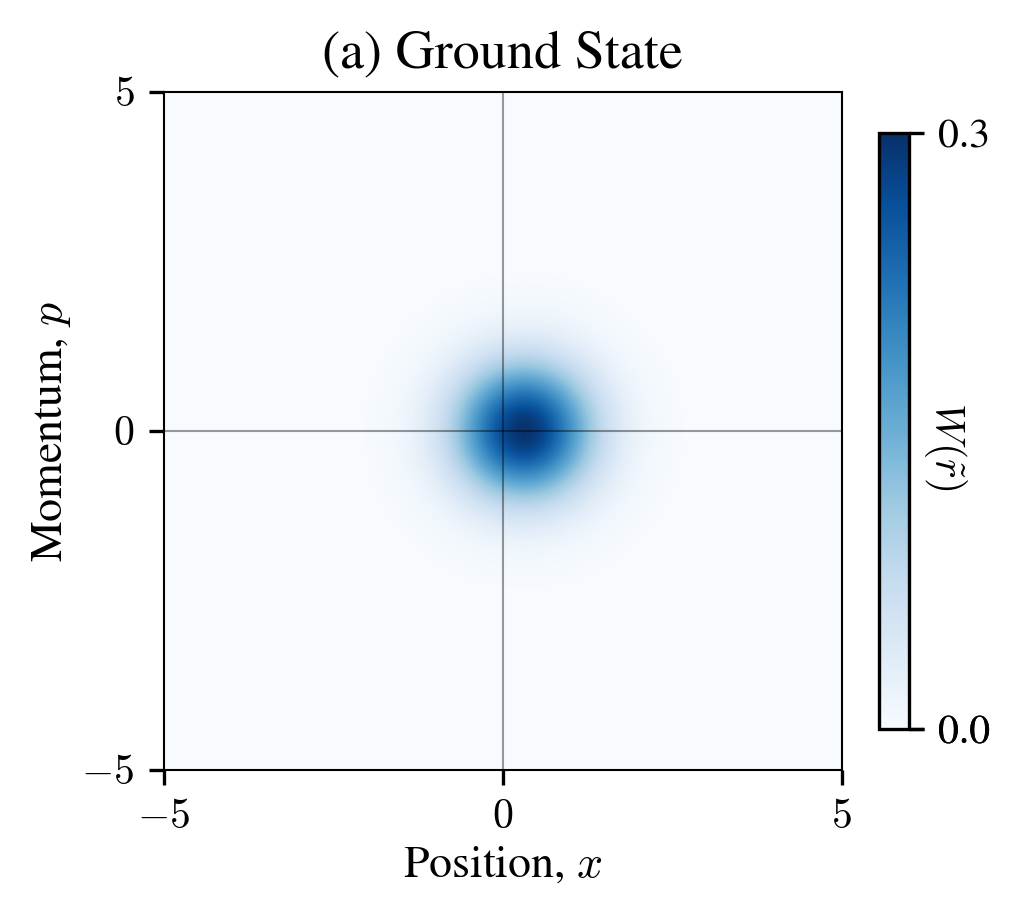

In [24]:
steps = 101
mode_number = 0
time_index = 40
bar_limits = [0,0.5]
sigma_para = 1.3
array_tick = np.linspace(-5,5,3)
n_frames = len(gaussian_state_general.t_array)

gaussian_state_general.Animate_Wigner_Function_Diag(steps, mode_number, sigma_para, array_tick, n_frames, title, 'Gaussian_Decay.gif')

## GCS Fringes: Classical Mixture and Quantum Interference
### Stern-Gerlach interferometer with initial coherent state

This is a time independent operator-valued force Hamiltonian
Initializing a Gaussian State
t[100] = 1.005 pi


/Users/lorenzobraccini/GitHub/GCS/src/Wigner_Functions.py:107: ComplexWarning: Casting complex values to real discards the imaginary part
  W_Diag[m,n] += (2**n_modes)*rho_q[i,i]/(np.pi**n_modes * np.sqrt(det_sigma))*np.exp(-np.transpose(r_tilde_array[m,n] - r_JK[i,i])@sigma_inv@(r_tilde_array[m,n] - r_JK[i,i]))[0,0]


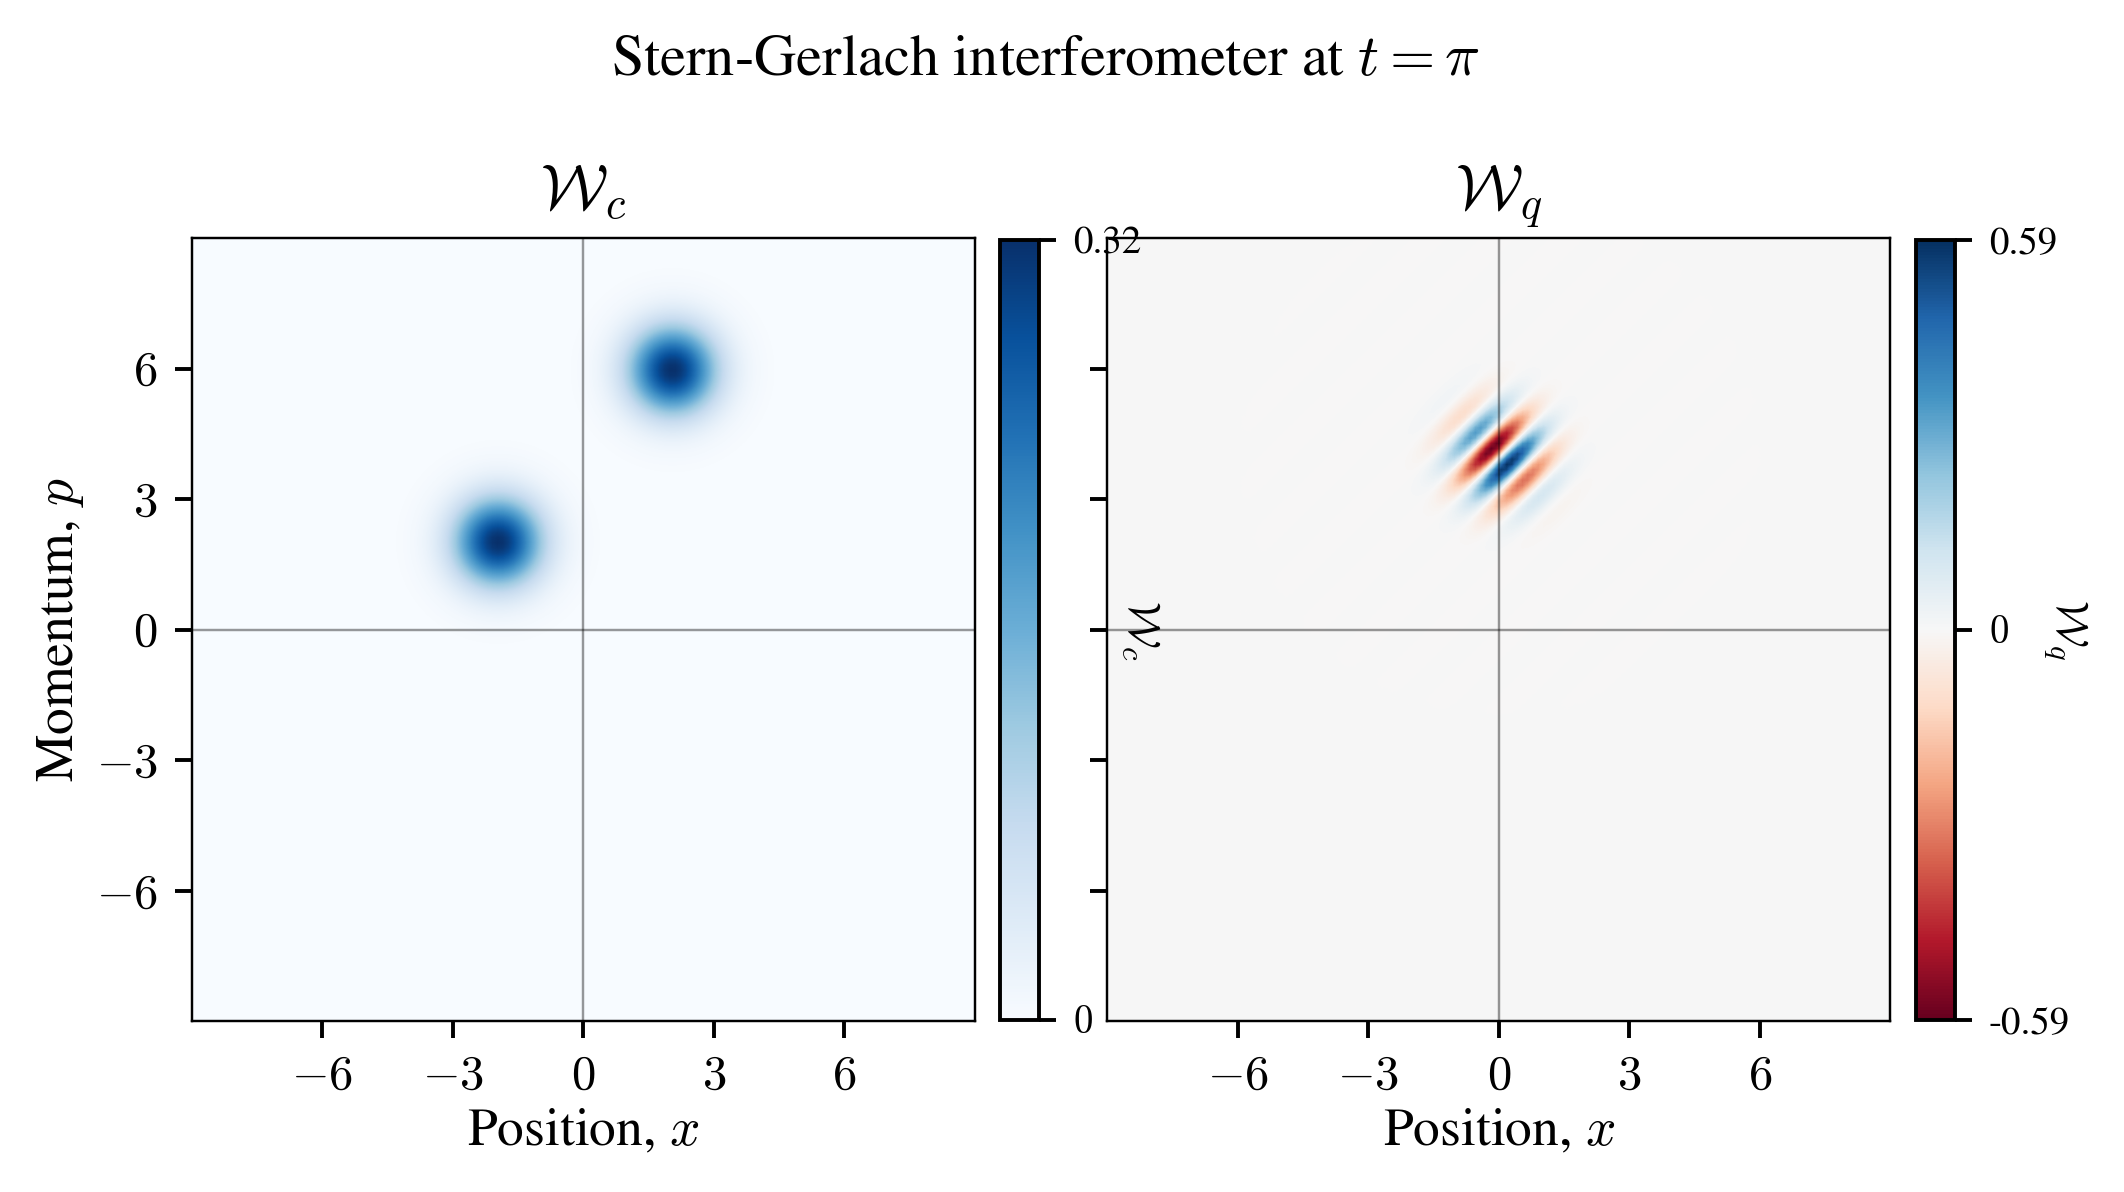

In [14]:
N_qubits = 1
n_modes  = 1

H_SG = Hamiltonian(N_qubits, n_modes)

H_m  = np.eye(2)                    # unit-frequency harmonic oscillator
r_m  =np.array([[0.0], [2.0]])              # no bias force
r_q = np.array([[1.0], [1.0]]) 
H_q_0_array = np.array([0.0 + 0j])

H_SG.Initialize_Constant_Hamiltonians([H_m], [r_m, r_q], H_q_0_array)

# Coherent state at origin; qubit in |+x> superposition
r_0      = np.zeros((2, 1))
sigma_0  = np.eye(2)
rho_q_0  = np.ones((2, 2)) / 2     # |+x><+x|

GCS_SG = Quantum_State(N_qubits, n_modes)
GCS_SG.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)

# Evolve over one full period [0, 2*pi]; t=pi is maximum superposition
t_array = np.linspace(0, 2 * np.pi, 200)
GCS_SG.Unitary_Dynamics_Numerical(H_SG, t_array)

t_pi_index = len(t_array) // 2
print(f"t[{t_pi_index}] = {t_array[t_pi_index] / np.pi:.3f} pi")

# Static side-by-side plot at t=pi
# At t=pi the two branches sit at x=+/-4, p=0; fringes appear in p direction
steps       = 150
mode_number = 0
sigma_para  = 2
array_tick  = 3*np.array([-2,-1,0,1, 2])

GCS_SG.Plot_Wigner_Function_GCS_Fringes(
    steps, t_pi_index, mode_number, sigma_para, array_tick,
    title=r'Stern-Gerlach interferometer at $t = \pi$',
    save='sg_fringes_2.svg')

In [32]:
print(1/np.pi)

0.3183098861837907


This is a time independent operator-valued general Hamiltonian
Initializing a Gaussian State
t[100] = 0.251 pi


/opt/anaconda3/lib/python3.11/site-packages/numpy/linalg/linalg.py:2180: RuntimeWarning: divide by zero encountered in det
  r = _umath_linalg.det(a, signature=signature)
/opt/anaconda3/lib/python3.11/site-packages/numpy/linalg/linalg.py:2180: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)
/Users/lorenzobraccini/GitHub/GCS/src/Wigner_Functions.py:107: ComplexWarning: Casting complex values to real discards the imaginary part
  W_Diag[m,n] += (2**n_modes)*rho_q[i,i]/(np.pi**n_modes * np.sqrt(det_sigma))*np.exp(-np.transpose(r_tilde_array[m,n] - r_JK[i,i])@sigma_inv@(r_tilde_array[m,n] - r_JK[i,i]))[0,0]


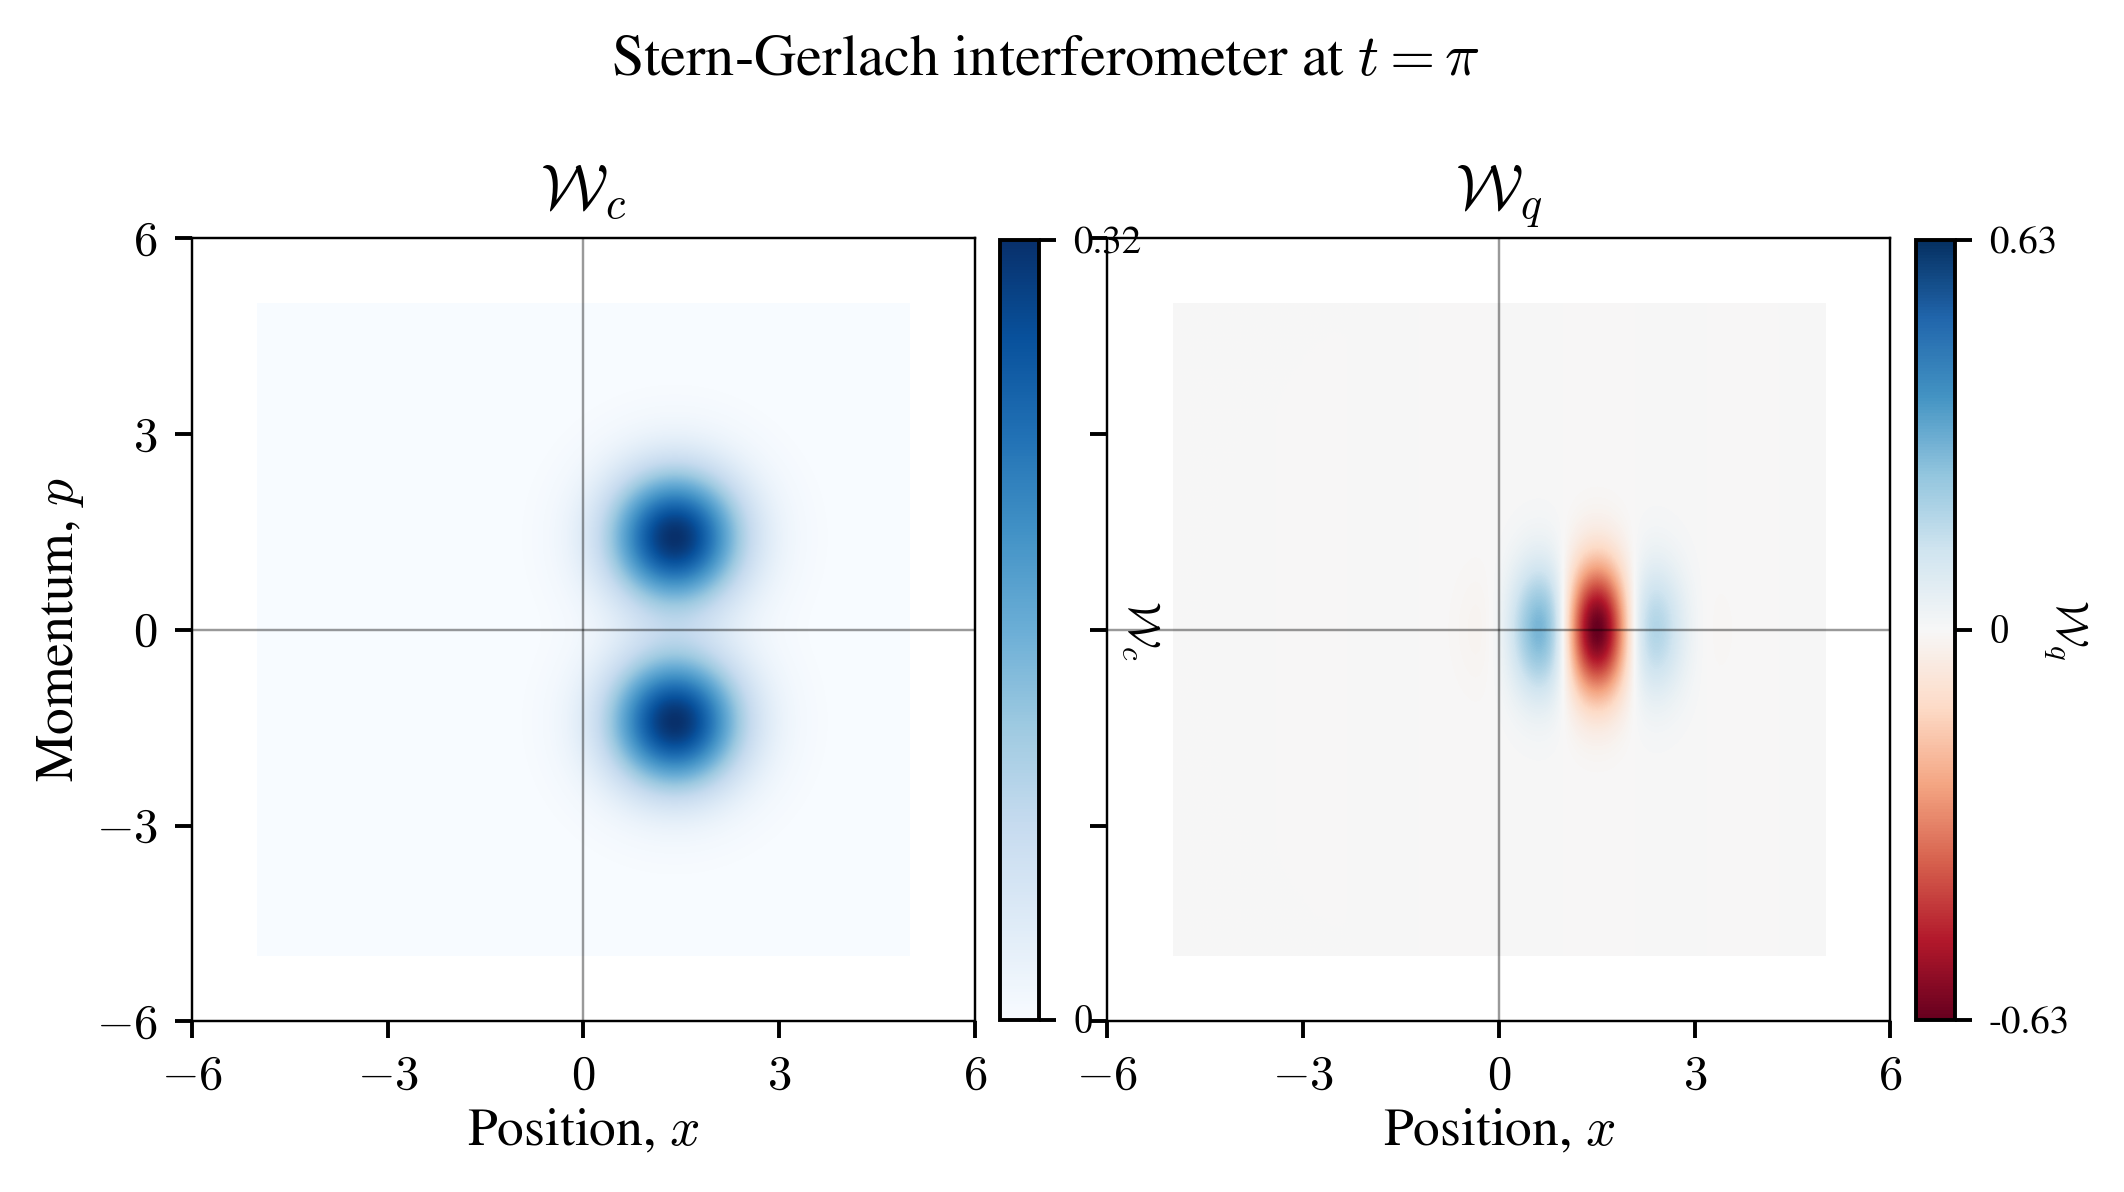

In [45]:
N_qubits = 1
n_modes  = 1

H_SG = Hamiltonian(N_qubits, n_modes)

H_m  = np.zeros((2,2))  
H_q  = np.eye(2)                    # unit-frequency harmonic oscillator
r_m  =np.array([[0.0], [0.0]])              # no bias force
r_q = np.array([[0.0], [0.0]]) 
H_q_0_array = np.array([0.0 + 0j])

H_SG.Initialize_Constant_Hamiltonians([H_m,H_q], [r_m, r_q], H_q_0_array)

# Coherent state at origin; qubit in |+x> superposition
r_0      = np.array([[2.0], [0.0]]) 
sigma_0  = np.eye(2)
rho_q_0  = np.ones((2, 2)) / 2     # |+x><+x|

GCS_SG = Quantum_State(N_qubits, n_modes)
GCS_SG.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)

# Evolve over one full period [0, 2*pi]; t=pi is maximum superposition
t_array = np.linspace(0, np.pi/2, 200)
GCS_SG.Unitary_Dynamics_Numerical(H_SG, t_array)

t_pi_index = len(t_array) // 2
print(f"t[{t_pi_index}] = {t_array[t_pi_index] / np.pi:.3f} pi")

# Static side-by-side plot at t=pi
# At t=pi the two branches sit at x=+/-4, p=0; fringes appear in p direction
steps       = 150
mode_number = 0
sigma_para  = 2
array_tick  = 3*np.array([-2,-1,0,1, 2])

GCS_SG.Plot_Wigner_Function_GCS_Fringes(
    steps, t_pi_index, mode_number, sigma_para, array_tick,
    title=r'Stern-Gerlach interferometer at $t = \pi$',
    save='sg_fringes_2.svg')

This is a time independent operator-valued general Hamiltonian
Initializing a Gaussian State


/opt/anaconda3/lib/python3.11/site-packages/numpy/linalg/linalg.py:2180: RuntimeWarning: divide by zero encountered in det
  r = _umath_linalg.det(a, signature=signature)
/opt/anaconda3/lib/python3.11/site-packages/numpy/linalg/linalg.py:2180: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)
/Users/lorenzobraccini/GitHub/GCS/src/Wigner_Functions.py:107: ComplexWarning: Casting complex values to real discards the imaginary part
  W_Diag[m,n] += (2**n_modes)*rho_q[i,i]/(np.pi**n_modes * np.sqrt(det_sigma))*np.exp(-np.transpose(r_tilde_array[m,n] - r_JK[i,i])@sigma_inv@(r_tilde_array[m,n] - r_JK[i,i]))[0,0]


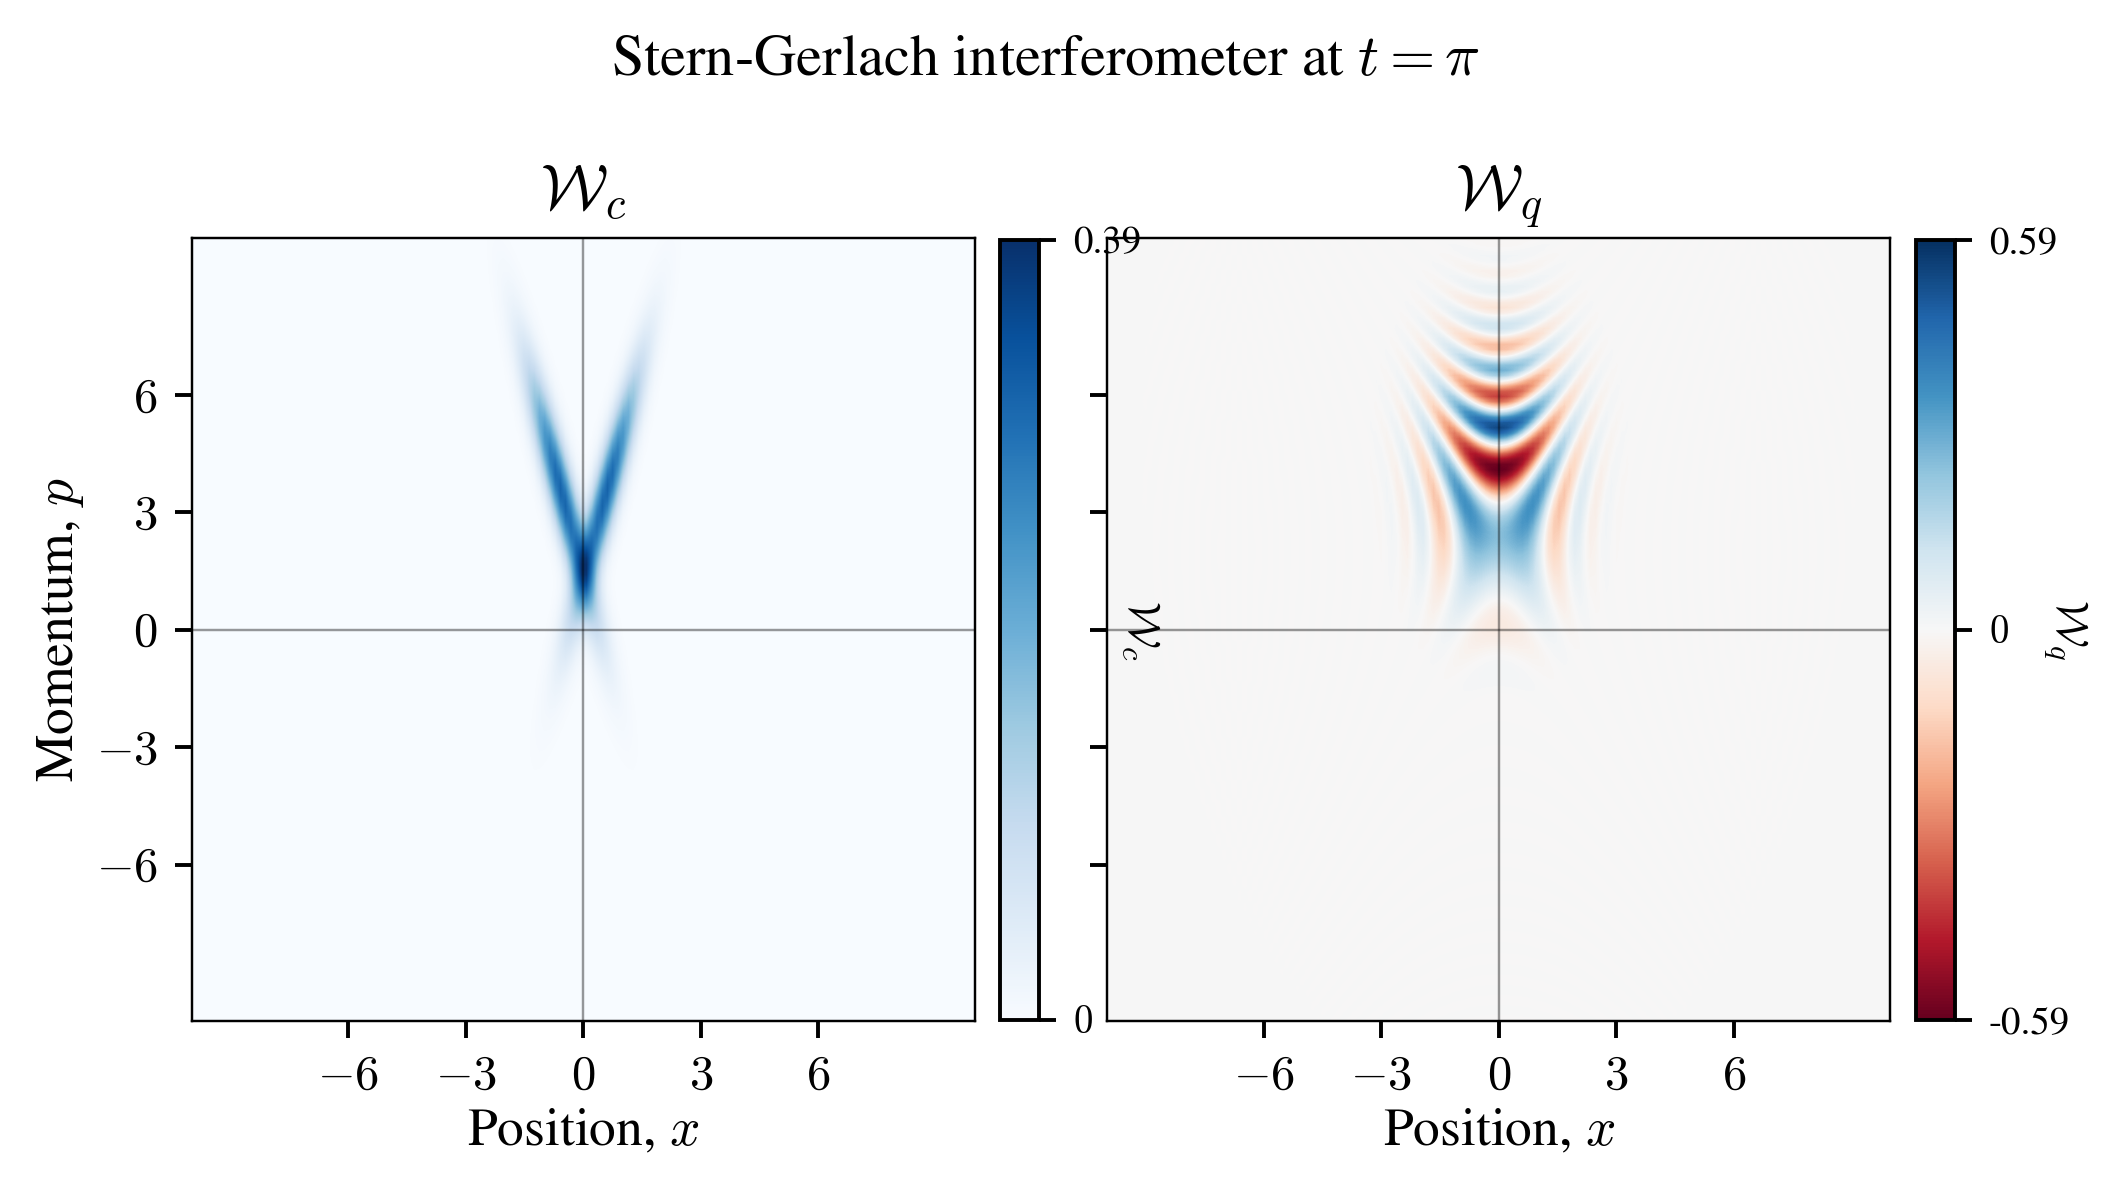

In [10]:
N_qubits = 1
n_modes  = 1

H_SG = Hamiltonian(N_qubits, n_modes)

H_m  = np.zeros((2,2))  
H_q  = np.eye(2)                    # unit-frequency harmonic oscillator
r_m  =np.array([[10.0], [0.0]])              # no bias force
r_q = np.array([[0.0], [0.0]]) 
H_q_0_array = np.array([0.0 + 0j])

H_SG.Initialize_Constant_Hamiltonians([H_m,H_q], [r_m, r_q], H_q_0_array)

s = 10
# Coherent state at origin; qubit in |+x> superposition
r_0      = np.array([[0], [1]]) 
sigma_0  = np.array([[1/s, 0],[0,s]])
rho_q_0  = np.ones((2, 2)) / 2     # |+x><+x|

GCS_SG = Quantum_State(N_qubits, n_modes)
GCS_SG.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)

# Evolve over one full period [0, 2*pi]; t=pi is maximum superposition
t_array = np.linspace(0, 0.25, 200)
GCS_SG.Unitary_Dynamics_Numerical(H_SG, t_array)

t_pi_index = len(t_array) -1

# Static side-by-side plot at t=pi
# At t=pi the two branches sit at x=+/-4, p=0; fringes appear in p direction
steps       = 150
mode_number = 0
sigma_para  = 0.6
array_tick  = 3*np.array([-2,-1,0,1, 2])

GCS_SG.Plot_Wigner_Function_GCS_Fringes(
    steps, t_pi_index, mode_number, sigma_para, array_tick,
    title=r'Stern-Gerlach interferometer at $t = \pi$',
    save='sg_fringes_cov.svg')

/opt/anaconda3/lib/python3.11/site-packages/numpy/linalg/linalg.py:2180: RuntimeWarning: divide by zero encountered in det
  r = _umath_linalg.det(a, signature=signature)
/opt/anaconda3/lib/python3.11/site-packages/numpy/linalg/linalg.py:2180: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)
/Users/lorenzobraccini/GitHub/GCS/src/Wigner_Functions.py:107: ComplexWarning: Casting complex values to real discards the imaginary part
  W_Diag[m,n] += (2**n_modes)*rho_q[i,i]/(np.pi**n_modes * np.sqrt(det_sigma))*np.exp(-np.transpose(r_tilde_array[m,n] - r_JK[i,i])@sigma_inv@(r_tilde_array[m,n] - r_JK[i,i]))[0,0]


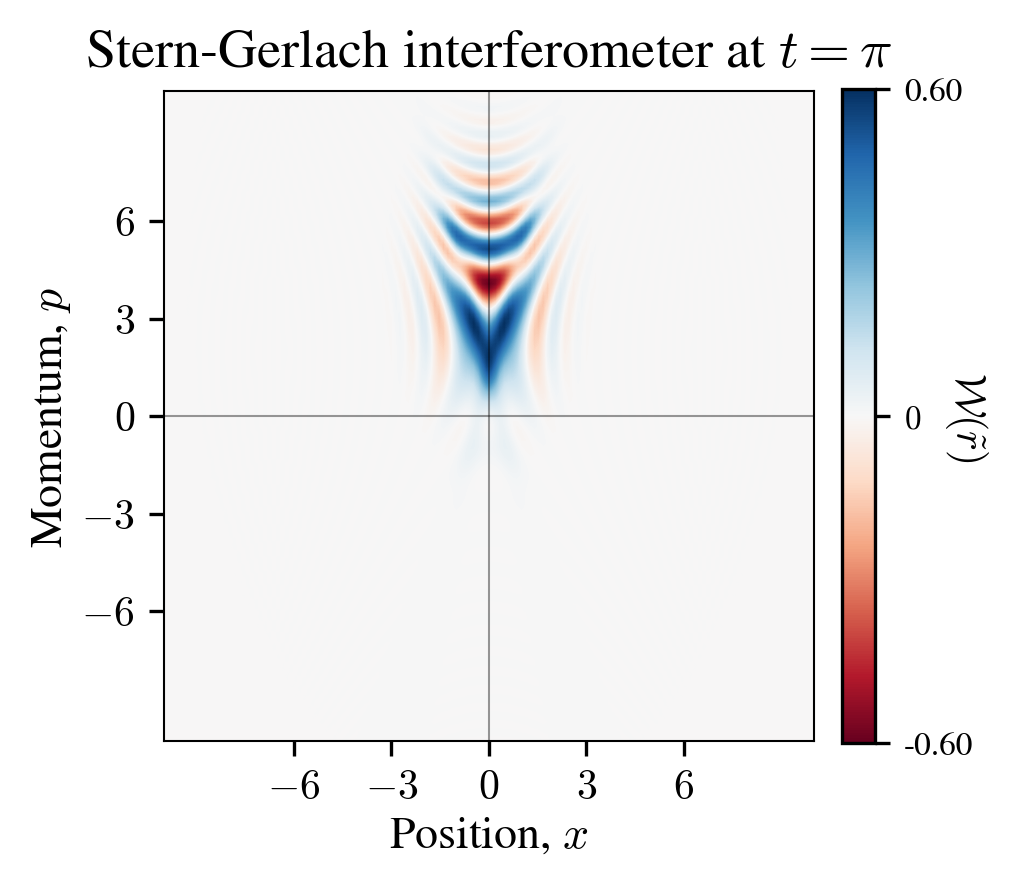

In [11]:
GCS_SG.Plot_Wigner_Function_GCS_Total(steps, t_pi_index, mode_number, sigma_para, array_tick,
    title=r'Stern-Gerlach interferometer at $t = \pi$',
    save='sg_fringes_cov_tot.svg')

/Users/lorenzobraccini/GitHub/GCS/src/Measurements.py:61: ComplexWarning: Casting complex values to real discards the imaginary part
  prob_t[i,j] = np.trace(rho_q_PMS_unnormalize)
/Users/lorenzobraccini/GitHub/GCS/src/Measurements.py:62: RuntimeWarning: invalid value encountered in divide
  rho_q_t_PMS_array[i,j] = rho_q_PMS_unnormalize/prob_t[i,j]
/opt/anaconda3/lib/python3.11/site-packages/numpy/linalg/linalg.py:2180: RuntimeWarning: divide by zero encountered in det
  r = _umath_linalg.det(a, signature=signature)
/opt/anaconda3/lib/python3.11/site-packages/numpy/linalg/linalg.py:2180: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)


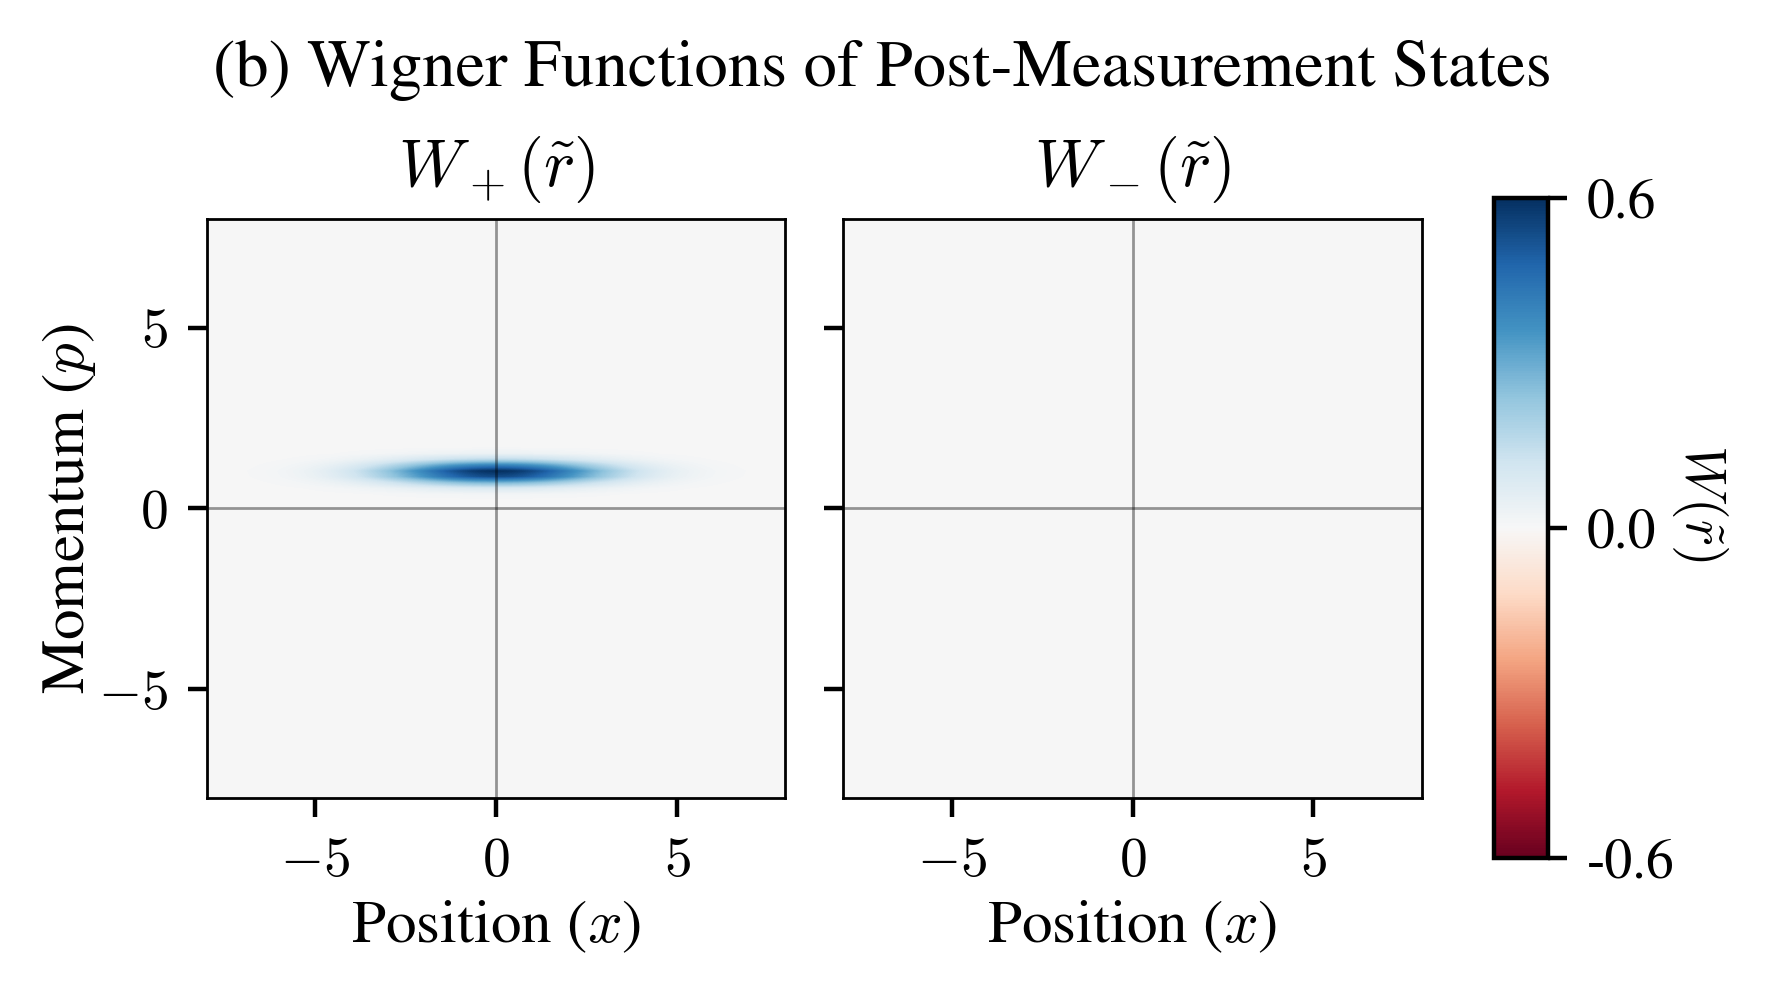

In [77]:
sigma_x = np.array([[0,1],[1,0]])/2 
steps = 100
mode_number = 0
time_index = 1
bar_limits = [0,0.5]
sigma_para = 0.7
array_tick = np.linspace(-5,5,3)
GCS_SG.Qubit_Ideal_Measurament(sigma_x, 'Time')
GCS_SG.Plot_Wigner_Function_PMS(steps, time_index, mode_number, sigma_para, array_tick, False, False)

In [ ]:
# Animation of W_c and W_q from t=0 to t=2*pi
n_frames = len(GCS_SG.t_array)

GCS_SG.Animate_Wigner_Function_GCS_Fringes(
    steps, mode_number, sigma_para, array_tick,
    n_frames, title='Stern-Gerlach GCS fringes',
    save='sg_fringes.gif')

/Users/lorenzobraccini/GitHub/GCS/src/Wigner_Functions.py:107: ComplexWarning: Casting complex values to real discards the imaginary part
  W_Diag[m,n] += (2**n_modes)*rho_q[i,i]/(np.pi**n_modes * np.sqrt(det_sigma))*np.exp(-np.transpose(r_tilde_array[m,n] - r_JK[i,i])@sigma_inv@(r_tilde_array[m,n] - r_JK[i,i]))[0,0]


## 3D Phase Space: Conditional Rotation (Δθ = θ̄ = π/6)

Conditional rotation of a squeezed state by branch-dependent angles $\theta_\pm = \bar\theta \pm \Delta\theta$.
The Hamiltonian is $H_\pm = (\bar\theta \pm \Delta\theta)\mathbb{1}$, i.e. $H_m = \bar\theta\,\mathbb{1}$, $H_q = \Delta\theta\,\mathbb{1}$ (General type).

For a squeezed initial state $\sigma_0 = \mathrm{diag}(1/s,\, s)$, the off-diagonal covariance acquires a complex structure at $\tau=1$:
$$
\sigma^{\mathrm{off}} = R_{\bar\theta}\,\mathrm{diag}\!\left(e^{i\psi}|\zeta|,\; e^{-i\psi}/|\zeta|\right) R_{\bar\theta}^T
$$
with $\zeta^2 = (\cos^2\!\Delta\theta + s^2\sin^2\!\Delta\theta)/(\sin^2\!\Delta\theta + s^2\cos^2\!\Delta\theta)$ and $\psi = \arctan\!\bigl(\tfrac12(s-1/s)\sin 2\Delta\theta\bigr)$.
This complex covariance is visualized as a **tilted pancake** in the $(Re[x],\,Re[p],\,Im[x])$ space.

In [ ]:
from gbcs import Plots_Functions as PF
from gbcs.Plots_Functions import (decompose_sigma_off_diagonal, transform_to_diagonal_frame,
                              Draw_Tilted_Pancake_3D, Draw_Ellipsoids, Draw_Vectors,
                              _make_scene_3d, _finalise_3d, Draw_XY_Plane, Sym_Lim_From_Data)

# ── Parameters ──────────────────────────────────────────────────────────────
Delta_theta = np.pi / 6   # Δθ = 30°
theta_bar   = np.pi / 6   # θ̄ = 30°
s_cr        = 3.0         # squeezing: σ_0 = diag(1/s, s)

N_qubits_cr = 1
n_modes_cr  = 1

# H_± = (θ̄ ± Δθ)·I  →  H_m = θ̄·I,  H_q = Δθ·I  (General type)
H_cond_rot = Hamiltonian(N_qubits_cr, n_modes_cr)
H_m_cr = theta_bar   * np.eye(2)
H_q_cr = Delta_theta * np.eye(2)
r_null_cr = np.zeros((2, 1))
H_cond_rot.Initialize_Constant_Hamiltonians(
    [H_m_cr, H_q_cr], [r_null_cr, r_null_cr], np.array([0.0+0j]))

# Initial state: squeezed, first moment at origin, fully mixed qubit
sigma_0_cr  = np.diag([1/s_cr, s_cr]).astype(complex)
r_0_cr      = np.zeros((2, 1))
rho_q_0_cr  = np.ones((2, 2)) / 2

GCS_cr = Quantum_State(N_qubits_cr, n_modes_cr)
GCS_cr.Initialize_Gaussian_State(r_0_cr, sigma_0_cr, rho_q_0_cr)

# τ ∈ [0, 1]:  at τ=1 the conditional rotation by Δθ, θ̄ is fully applied
t_cr = np.linspace(0, 1, 80)
GCS_cr.Unitary_Dynamics_Numerical(H_cond_rot, t_cr)
print("σ^off at τ = 1 (numerical):")
print(np.round(GCS_cr.sigma_JK_t[-1, 0, 1], 5))

In [ ]:
# ── Analytical formula (paper Appendix, Eq. cov_rotation) ───────────────────
c2_cr = np.cos(Delta_theta)**2
s2_cr = np.sin(Delta_theta)**2
zeta_cr = np.sqrt((c2_cr + s_cr**2 * s2_cr) / (s2_cr + s_cr**2 * c2_cr))
psi_cr  = np.arctan2((s_cr - 1/s_cr) * np.sin(2 * Delta_theta), 2.0)

R_bar_cr = np.array([[np.cos(theta_bar), -np.sin(theta_bar)],
                      [np.sin(theta_bar),  np.cos(theta_bar)]])
Sigma_analytic = np.diag([np.exp(1j * psi_cr) * zeta_cr,
                           np.exp(-1j * psi_cr) / zeta_cr])
sigma_off_analytic = R_bar_cr @ Sigma_analytic @ R_bar_cr.T

print(f"ζ = {zeta_cr:.4f},   ψ/π = {psi_cr/np.pi:.4f}")
print("\nAnalytical σ^off at τ=1:")
print(np.round(sigma_off_analytic, 5))
print("\nMax |numerical - analytical|:",
      np.max(np.abs(GCS_cr.sigma_JK_t[-1, 0, 1] - sigma_off_analytic)))

In [ ]:
# ── 3D phase-space snapshot at τ=1 ──────────────────────────────────────────
# Decompose σ^off and print frame info
from gbcs.Plots_Functions import decompose_sigma_off_diagonal
U_cr, _, mags_cr, phases_cr = decompose_sigma_off_diagonal(GCS_cr.sigma_JK_t[-1, 0, 1])
print(f"Decomposed σ^off:  |Σ₁₁| = {mags_cr[0]:.4f}  ψ₁ = {phases_cr[0]/np.pi:.4f}π")
print(f"                   |Σ₂₂| = {mags_cr[1]:.4f}  ψ₂ = {phases_cr[1]/np.pi:.4f}π")
print(f"Rotation U:\n{np.round(U_cr, 4)}")

GCS_cr.Plot_3D_Diagonal_Sigma(
    t_idx=-1, z_comp=0, sym_lim=(-2, 2),
    title=r'Conditional rotation: $\Delta\theta = \bar\theta = \pi/6$, $s = 3$',
    elev=28, azim=-50, save='cond_rot_3d.png')

## Example 1: Dispersive Coupling + Parametric Amplifier — Steady State

The Hamiltonian $H_\pm = \lambda\sigma_x \pm \mu\,\mathbb{1}$ describes a qubit dispersively coupled ($\mu$) to a resonator with a parametric amplifier ($\lambda$), where $\sigma_x = \bigl[\!\begin{smallmatrix}0&1\\1&0\end{smallmatrix}\!\bigr]$ in $(x,p)$ phase space. Cavity decay at rate $\kappa$ (photon loss) drives the system to a steady state.

By varying the driving quadrature one accesses two regimes:
- **Amplified** ($\phi_d = 0$): drive along $x$, so $r_m = A(1,0)^T$
- **Squeezed** ($\phi_d = \pi/2$): drive along $p$, so $r_m = A(0,1)^T$

Setting $\lambda = 0$ (no parametric amplification) collapses the system to a coherent-state regime: $\sigma^{\mathrm{off}}$ remains real (identity), so the pancake lies flat in the $(Re[x],\,Re[p])$ plane.

In [3]:
def simulate_dispersive_pa(lam, mu, kappa, r_drive, T_final=40, n_steps=600):
    """Open dynamics of dispersive coupling + parametric amplifier to steady state.

    H_± = lam * [[0,1],[1,0]] ± mu * I,  photon loss at rate kappa.
    r_drive is the Hamiltonian force vector (coherent driving).
    Stability requires kappa > 2*lam.
    """
    N_qubits_pa = 1
    n_modes_pa  = 1
    sigma_x_ps  = np.array([[0., 1.], [1., 0.]])   # σ_x in (x,p) phase space

    H_pa = Hamiltonian(N_qubits_pa, n_modes_pa)
    H_pa.Initialize_Constant_Hamiltonians(
        [lam * sigma_x_ps, mu * np.eye(2)],
        [r_drive, np.zeros((2, 1))],
        np.array([0.0 + 0j]))

    B_loss = kappa * np.array([[0., 1.], [0., 0.]])   # photon loss in Ladder basis
    Dec_pa = Decoherence(N_qubits_pa, n_modes_pa, 'Ladder', B_loss)

    GCS_pa = Quantum_State(N_qubits_pa, n_modes_pa)
    GCS_pa.Initialize_Gaussian_State(
        np.zeros((2, 1)),
        np.eye(2, dtype=complex),
        np.ones((2, 2)) / 2)

    t_pa = np.linspace(0, T_final, n_steps)
    GCS_pa.Open_Dynamics_Numerical(H_pa, Dec_pa, t_pa)
    return GCS_pa

# ── Physical parameters ─────────────────────────────────────────────────────
mu_pa    = 1.0   # dispersive coupling
kappa_pa = 2.0   # cavity decay  (must satisfy kappa > 2*lambda for stability)
lam_pa   = 0.5   # parametric amplification
A_pa     = 5.0   # drive amplitude

r_ampl   = A_pa * np.array([[1.0], [0.0]])   # φ_d = 0   (amplified)
r_squeez = A_pa * np.array([[0.0], [1.0]])   # φ_d = π/2 (squeezed)

print(f"Running λ=0 (coherent) ...")
GCS_coh = simulate_dispersive_pa(0.0,    mu_pa, kappa_pa, r_ampl)
print(f"Running λ={lam_pa}, amplified (φ_d=0) ...")
GCS_amp = simulate_dispersive_pa(lam_pa, mu_pa, kappa_pa, r_ampl)
print(f"Running λ={lam_pa}, squeezed (φ_d=π/2) ...")
GCS_sq  = simulate_dispersive_pa(lam_pa, mu_pa, kappa_pa, r_squeez)
print("Done.")

Running λ=0 (coherent) ...
This is a time independent operator-valued general Hamiltonian
Initializing a Gaussian State
Running λ=0.5, amplified (φ_d=0) ...
This is a time independent operator-valued general Hamiltonian
Initializing a Gaussian State
Running λ=0.5, squeezed (φ_d=π/2) ...
This is a time independent operator-valued general Hamiltonian
Initializing a Gaussian State
Done.


In [ ]:
z_comp_pa = 0

print("λ = 0 (coherent regime)")
GCS_coh.Plot_3D_Diagonal_Sigma(
    t_idx=-1, z_comp=z_comp_pa,
    title=r'Dispersive coupling, $\lambda=0$ (coherent regime)',
    elev=28, azim=-50, save='pa_lambda0_3d.png')

print("\nλ = 0.5, amplified (φ_d = 0)")
GCS_amp.Plot_3D_Diagonal_Sigma(
    t_idx=-1, z_comp=z_comp_pa,
    title=r'Dispersive+PA, $\lambda=0.5$, amplified ($\phi_d=0$)',
    elev=28, azim=-40, save='pa_amplified_3d.png')

print("\nλ = 0.5, squeezed (φ_d = π/2)")
GCS_sq.Plot_3D_Diagonal_Sigma(
    t_idx=-1, z_comp=z_comp_pa,
    title=r'Dispersive+PA, $\lambda=0.5$, squeezed ($\phi_d=\pi/2$)',
    elev=28, azim=-40, save='pa_squeezed_3d.png')

## Example 2: Stern-Gerlach Interferometer (Section 9B)

Hamiltonian $H = \mathbb{1} + r_{\pm} \cdot \hat{r}$ with $r_{\pm} = r_m \pm r_q$,  $r_m = (f_u, 0)^T$,  $r_q = (f_q, 0)^T$.
This is the **Force** type (single $H_m = \mathbb{1}$, two force vectors).

Initial state: squeezed thermal state $\sigma_0 = (1+2N_p)\,\mathrm{diag}(s,\, 1/s)$,  $r_0 = 0$,  $\rho^q_0 = \tfrac{1}{2}\mathbb{1}$.

Decoherence: $B = \Gamma_x\,|x\rangle\langle x|$ (canonical) $\;\Rightarrow\; E = 0$, $D = \mathrm{diag}(0,\, 2\Gamma_x)$.

**Checks (paper Appendix + Sec. 9B, code convention $S = e^{\tau\Omega}$)**:
- $\sigma(\tau)$: closed-form integral of $S(\tau-t)\,D\,S(\tau-t)^T$
- $r^{\mathrm{on}}_J(\tau) = (f_u + J f_q)(1-\cos\tau,\; \sin\tau)^T$  ← code convention sign
- $\bar{r}^{\mathrm{off}}(\tau)$: paper formula (real part has $+\sin\tau$, consistent with code)
- $C(\tau)$: scalar, convention-independent

In [ ]:
# ── Stern-Gerlach interferometer (Sec. 9B) — paper appendix vs. numerical library ──
#
# CONVENTION NOTE.  The paper defines Omega_1 = [[0,1],[-1,0]] (Sec. II), which is
# exactly what Gaussian.Omega_N returns.  With that Omega,
#       S_qho(tau) = exp(tau*Omega*H) = [[cos, sin], [-sin, cos]] ,
# i.e. the TRANSPOSE of the matrix printed in the appendix.  Everything below is
# written in the paper's own Omega convention; where the printed appendix formula
# disagrees, the deviation is flagged as [ERRATUM].
#
# Branch indexing: Extract_Qubit_Labels_Array maps 2*bit-1, so for N=1
#       index 0 -> J = -1        index 1 -> J = +1
# hence r_JK_t[:,1,1] is r^on_+ and r_JK_t[:,0,0] is r^on_-, and the paper's
# r^off is the (j,k) = (-1,+1) element, i.e. r_JK_t[:,0,1].

f_u     = 0.5    # bias force
f_q     = 2.0    # qubit-dependent force
N_p     = 0.8    # mean thermal photons
s       = 2.0    # squeezing  (sigma_0 = (1+2Np)*diag(s, 1/s))
Gamma_x = 0.1    # position-diffusion rate

H_m_sg2 = np.eye(2)
r_m_sg2 = np.array([[f_u], [0.0]])
r_q_sg2 = np.array([[f_q], [0.0]])

H_SG2 = Hamiltonian(1, 1)
H_SG2.Initialize_Constant_Hamiltonians([H_m_sg2], [r_m_sg2, r_q_sg2], np.array([0.0 + 0j]))
print("Hamiltonian type:", H_SG2.type)   # ['Constant', 'Force']

sigma_0_sg2 = (1 + 2*N_p) * np.diag([s, 1/s])
r_0_sg2     = np.zeros((2, 1))
rho_q_0_sg2 = np.ones((2, 2)) / 2        # |+x><+x|

# B = Gamma_x * |x><x|  =>  E = 0, D = diag(0, 2*Gamma_x)
Dec_sg2 = Decoherence(1, 1, 'Canonical', Gamma_x * np.array([[1., 0.], [0., 0.]]))
print("E_mat =\n", np.round(Dec_sg2.E_mat, 6))
print("D_mat =\n", np.round(Dec_sg2.D_mat, 6))

t_array_sg2 = np.linspace(0.15, 2*np.pi, 300)

# ── Numerical: Hamiltonian-driven, no known symplectic transformation used ──
GCS_SG2_u = Quantum_State(1, 1)
GCS_SG2_u.Initialize_Gaussian_State(r_0_sg2, sigma_0_sg2, rho_q_0_sg2)
GCS_SG2_u.Unitary_Dynamics_Numerical(H_SG2, t_array_sg2)

GCS_SG2_d = Quantum_State(1, 1)
GCS_SG2_d.Initialize_Gaussian_State(r_0_sg2, sigma_0_sg2, rho_q_0_sg2)
GCS_SG2_d.Open_Dynamics_Numerical(H_SG2, Dec_sg2, t_array_sg2)
print("\nRuns complete.\n")


# ── Analytical formulas (paper appendix, in the paper's own Omega convention) ──

def sg2_sigma(tau, Gx):
    """Covariance matrix. Printed form is correct (convention-independent)."""
    c, sn = np.cos(tau), np.sin(tau)
    return ((1 + 2*N_p) * np.array([[s*c**2 + sn**2/s,  (1/s - s)*sn*c],
                                    [(1/s - s)*sn*c,    s*sn**2 + c**2/s]])
            + Gx * np.array([[tau - sn*c,  sn**2],
                             [sn**2,       tau + sn*c]]))

def sg2_r_on(tau, J):
    """[ERRATUM] Printed as (f_u -+ f_q)(1-cos, -sin) for r^on_+-.
    With Omega = [[0,1],[-1,0]] the correct form is (f_u + J f_q)(1-cos, +sin):
    the -+ should be +- (cf. the tau=pi values, quoted with +- later in the paper),
    and the -sin follows the transposed S_qho typo."""
    c, sn = np.cos(tau), np.sin(tau)
    return (f_u + J*f_q) * np.array([1 - c, sn])

def sg2_r_off(tau, Gx):
    """Printed form is correct, and corresponds to (j,k) = (-1,+1) = r_JK_t[:,0,1]."""
    c, sn = np.cos(tau), np.sin(tau)
    s2 = np.sin(tau/2)**2
    return (f_u * np.array([1 - c, sn])
            + 1j*f_q*((1 + 2*N_p) * np.array([sn*((1/s - s)*c - 1/s),
                                              2*s2*((s - 1/s)*c + s)])
                      + Gx * np.array([-4*s2**2, tau + sn*(c - 2)])))

def sg2_C(tau, Gx):
    """Printed form is correct (Gamma_z = Gamma_1 = 0)."""
    c, sn = np.cos(tau), np.sin(tau)
    s2 = np.sin(tau/2)**2
    return f_q**2 * (2*(1 + 2*N_p)*s2*((s - 1/s)*c + s + 1/s)
                     + Gx*(3*tau + sn*(c - 4)))

def sg2_phi(tau):
    """[ERRATUM] Printed as 2 f_q f_u (tau + sin tau); correct is (tau - sin tau),
    again the transposed-S_qho typo.  It is the (j,k) = (+1,-1) element,
    i.e. phi_JK_t[:,1,0] -- the OPPOSITE ordering to the printed r^off."""
    return 2*f_q*f_u*(tau - np.sin(tau))


# ── Verification over the whole time axis ─────────────────────────────────────
_e = lambda a, b: np.max(np.abs(np.asarray(a) - np.asarray(b)))

print("=" * 72)
print(f"{'quantity':<26}{'unitary':>20}{'diffusive':>20}")
print("-" * 72)
rows = {k: [0.0, 0.0] for k in
        ('sigma', 'r^on_+  [1,1]', 'r^on_-  [0,0]', 'r^off   [0,1]', 'C  [0,1]', 'phi  [1,0]')}
for col, (G, Gx) in enumerate(((GCS_SG2_u, 0.0), (GCS_SG2_d, Gamma_x))):
    for i, tau in enumerate(t_array_sg2):
        r = rows
        r['sigma'][col]        = max(r['sigma'][col],        _e(np.real(G.sigma_JK_t[i,0,0]), sg2_sigma(tau, Gx)))
        r['r^on_+  [1,1]'][col] = max(r['r^on_+  [1,1]'][col], _e(np.real(G.r_JK_t[i,1,1,:,0]), sg2_r_on(tau, +1)))
        r['r^on_-  [0,0]'][col] = max(r['r^on_-  [0,0]'][col], _e(np.real(G.r_JK_t[i,0,0,:,0]), sg2_r_on(tau, -1)))
        r['r^off   [0,1]'][col] = max(r['r^off   [0,1]'][col], _e(G.r_JK_t[i,0,1,:,0],         sg2_r_off(tau, Gx)))
        r['C  [0,1]'][col]      = max(r['C  [0,1]'][col],      abs(G.C_JK_t[i,0,1]   - sg2_C(tau, Gx)))
        r['phi  [1,0]'][col]    = max(r['phi  [1,0]'][col],    abs(G.phi_JK_t[i,1,0] - sg2_phi(tau)))
for k, (a, b) in rows.items():
    print(f"{k:<26}{a:>20.3e}{b:>20.3e}")
print("-" * 72)
print("max |numerical - analytical| over all 300 times")
print("=" * 72)

# ── Special values quoted in the appendix ─────────────────────────────────────
for tau_c, name in [(np.pi, 'pi'), (2*np.pi, '2pi')]:
    i = np.argmin(np.abs(t_array_sg2 - tau_c))
    print(f"\ntau = {name}  (t[{i}] = {t_array_sg2[i]:.5f})")
    ref = (f"   paper: 2(f_u +- f_q) = {2*(f_u+f_q):.4f} / {2*(f_u-f_q):.4f}  [printed with -+]"
           if name == 'pi' else "   paper: (0, 0)  -- interferometer recombined")
    print(f"  r^on_+  = {np.round(np.real(GCS_SG2_d.r_JK_t[i,1,1,:,0]), 4)}{ref}")
    print(f"  r^on_-  = {np.round(np.real(GCS_SG2_d.r_JK_t[i,0,0,:,0]), 4)}")
    print(f"  r^off   = {np.round(GCS_SG2_d.r_JK_t[i,0,1,:,0], 4)}")
    print(f"            {np.round(sg2_r_off(t_array_sg2[i], Gamma_x), 4)}  (paper)")
    print(f"  C       = {GCS_SG2_d.C_JK_t[i,0,1]:.5f}   paper: {sg2_C(t_array_sg2[i], Gamma_x):.5f}")
    print(f"  phi     = {GCS_SG2_d.phi_JK_t[i,1,0]:.5f}   paper: {sg2_phi(t_array_sg2[i]):.5f}")


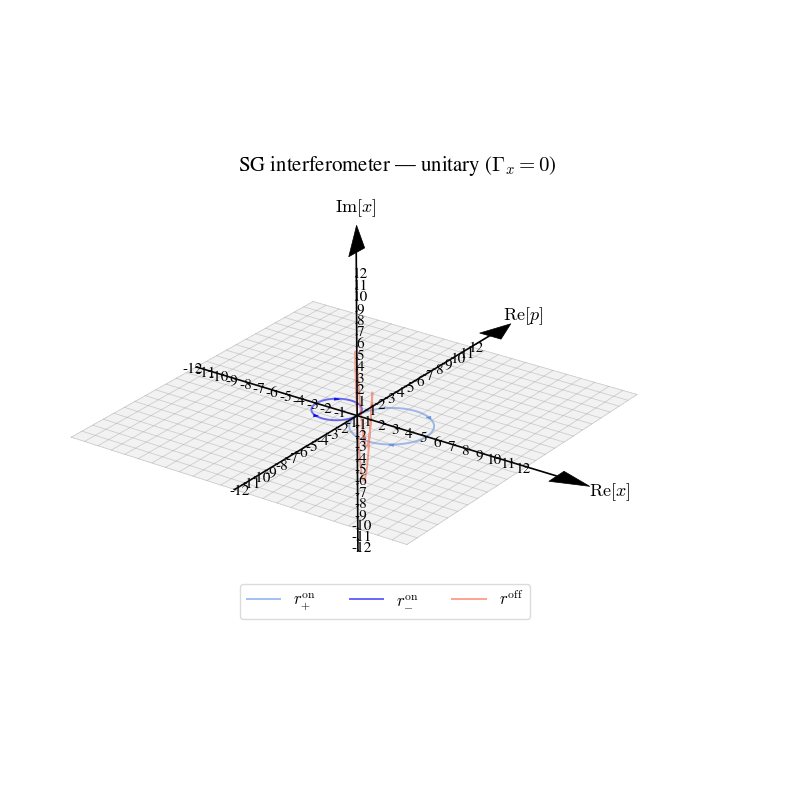

In [4]:
# ── 3D trajectory: unitary ───────────────────────────────────────────────────
# On-diagonal (real) branches trace closed loops in z=0 plane.
# Off-diagonal acquires a purely imaginary component → height in Im[x] axis.
fig_u, ax_u = GCS_SG2_u.Plot_Trajectories_Single(
    z_comp=0,
    title=r'SG interferometer — unitary ($\Gamma_x = 0$)',
    elev=25, azim=-55,
    save='sg2_trajectories_unitary.png')
plt.show()

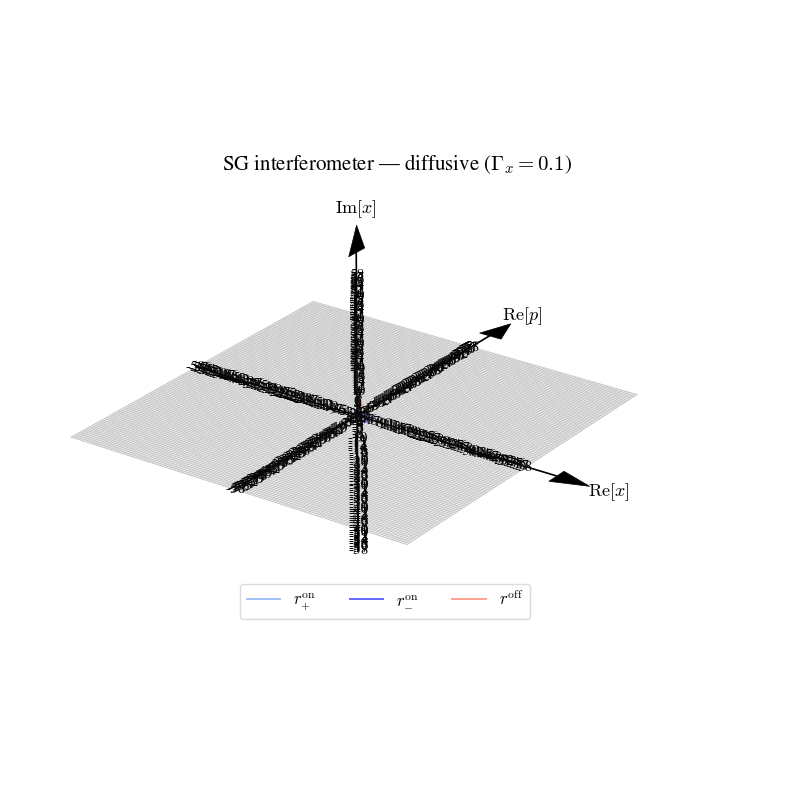

In [34]:
# ── 3D trajectory: diffusive ─────────────────────────────────────────────────
# Diffusion (Γ_x > 0) adds a growing Im[r^off_x] component.
# On-diagonal loops remain in z=0 (r^on is real and unchanged by diffusion).
# The off-diagonal trajectory spirals out of the z=0 plane as τ increases,
# ending at a non-zero Im[x] at τ=2π (marker of decoherence).
fig_d, ax_d = GCS_SG2_d.Plot_Trajectories_Single(
    z_comp=0,
    title=r'SG interferometer — diffusive ($\Gamma_x = 0.1$)',
    elev=25, azim=-55,
    save='sg2_trajectories_diffusive.png')
plt.show()